# Árboles de decisión, Boosting y XGBoost
### De las bases teóricas al algoritmo y sus hiperparámetros

Este cuaderno recorre, de forma progresiva y con código ejecutable, la familia de modelos basados en árboles que domina el aprendizaje automático sobre datos tabulares. Se parte de la idea más elemental (dividir el espacio de características en regiones) y se llega a XGBoost, pasando por el *boosting* y el descenso de gradiente en el espacio de funciones.

**Contenido**

0. Preparación del entorno y notación
1. Árboles de decisión: fundamentos, impureza, algoritmo CART, sobreajuste y poda
2. Ensambles y *boosting*: sesgo-varianza, AdaBoost y *Gradient Boosting*
3. XGBoost: objetivo regularizado, *similarity score*, ganancia, $\lambda$, $\gamma$, *cover*, algoritmo completo y búsqueda de cortes
4. Hiperparámetros: listado, efecto de cada uno, *early stopping*, importancia de variables y receta de ajuste
5. Comparación global
6. Ejercicios (5)
7. Soluciones
8. Referencias

**Cómo usar el cuaderno.** Las celdas se ejecutan en orden. Las celdas marcadas como **[Interactivo]** usan controles deslizantes (`ipywidgets`) y requieren un kernel activo; cada una va acompañada de una versión estática para poder leer los resultados sin ejecutar nada. Los ejemplos numéricos pequeños están pensados para poder verificarse a mano.

## 0. Preparación y notación

Dependencias: `numpy`, `pandas`, `matplotlib`, `scikit-learn`, `xgboost` e `ipywidgets`.

```bash
pip install numpy pandas matplotlib scikit-learn xgboost ipywidgets
```

**Notación utilizada**

| Símbolo | Significado |
|---|---|
| $\mathbf{x}_i \in \mathbb{R}^p$, $y_i$ | observación $i$ (de $n$) con $p$ características, y su objetivo |
| $\hat y_i$ | predicción del modelo para la observación $i$ |
| $R_m$ | región (hoja) $m$ de un árbol; $T$ = número de hojas |
| $I(\cdot)$ | impureza de un nodo (Gini, entropía, varianza…) |
| $l(y,\hat y)$ | función de pérdida por observación |
| $g_i,\ h_i$ | primera y segunda derivada de $l$ respecto de $\hat y$ (gradiente y hessiano) |
| $G_j=\sum_{i\in I_j} g_i,\ H_j=\sum_{i\in I_j} h_i$ | sumas de gradientes y hessianos en la hoja $j$ |
| $w_j$ | valor (peso) de salida de la hoja $j$ |
| $\lambda,\ \gamma,\ \alpha$ | regularización L2 sobre pesos, penalización por hoja, regularización L1 |
| $\eta$ | tasa de aprendizaje (*learning rate*, *shrinkage*) |

In [48]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.datasets import make_moons, make_friedman1, make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, mean_squared_error, roc_auc_score,
                             precision_score, recall_score)
from sklearn.inspection import permutation_importance
import xgboost as xgb

import ipywidgets as widgets
from ipywidgets import interact, IntSlider, FloatSlider, FloatLogSlider, Dropdown, fixed

warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.labelsize": 10})

def rmse(y, yhat):
    return float(np.sqrt(mean_squared_error(y, yhat)))

print("XGBoost", xgb.__version__)

XGBoost 3.4.1


---
# 1. Árboles de decisión

## 1.1 La idea: partición recursiva del espacio

Un **árbol de decisión** divide el espacio de características en regiones rectangulares disjuntas $R_1,\dots,R_T$ mediante una secuencia de preguntas binarias del tipo "¿$x_j < t$?", y asigna una predicción constante a cada región:

$$
f(\mathbf{x}) \;=\; \sum_{m=1}^{T} c_m\,\mathbb{1}\!\left[\mathbf{x}\in R_m\right].
$$

Terminología: el **nodo raíz** contiene todos los datos; los **nodos internos** contienen una regla de corte (*split*) $(j,t)$; las **hojas** contienen la predicción $c_m$; la **profundidad** es la longitud del camino más largo de la raíz a una hoja.

* **Regresión:** $c_m$ es la media de $y$ en la región (minimiza el error cuadrático dentro de ella).
* **Clasificación:** $c_m$ es la clase mayoritaria, o las proporciones de clase $\hat p_{mk}$ en la región.

## 1.2 Medidas de impureza y ganancia

Un buen corte produce nodos hijos más **homogéneos** (puros) que el padre. Para un nodo con proporciones de clase $p_1,\dots,p_K$:

$$
\text{Gini}=1-\sum_{k} p_k^2, \qquad
\text{Entropía}=-\sum_{k} p_k\log_2 p_k .
$$

En regresión, la impureza del nodo es la varianza (o, equivalentemente, el error cuadrático medio respecto a la media del nodo):

$$
I(t)=\frac1{n_t}\sum_{i\in t}\left(y_i-\bar y_t\right)^2 .
$$

La **ganancia** de un corte que separa el nodo $t$ en $t_L$ y $t_R$ es la reducción de impureza ponderada por el tamaño de los hijos:

$$
\Delta I \;=\; I(t)\;-\;\frac{n_L}{n_t}\,I(t_L)\;-\;\frac{n_R}{n_t}\,I(t_R).
$$

> **Ejemplo 1.1.** Se tienen 10 observaciones con una sola característica $x$ y una etiqueta binaria. Se evalúan todos los umbrales candidatos (puntos medios entre valores consecutivos) con Gini y con entropía.

Impureza del nodo raíz -> Gini = 0.500 | entropía = 1.000


,umbral,Gini izq,Gini der,Ganancia (Gini),Ganancia (entropía)
0,1.5,0.0000,0.4938,0.0556,0.1080
1,2.5,0.0000,0.4688,0.1250,0.2365
2,3.5,0.0000,0.4082,0.2143,0.3958
3,4.5,0.3750,0.4444,0.0833,0.1245
4,5.5,0.3200,0.3200,0.1800,0.2781
5,6.5,0.4444,0.3750,0.0833,0.1245
6,7.5,0.4898,0.4444,0.0238,0.0349
7,8.5,0.5000,0.5000,0.0000,0.0000
8,9.5,0.4938,0.0000,0.0556,0.1080


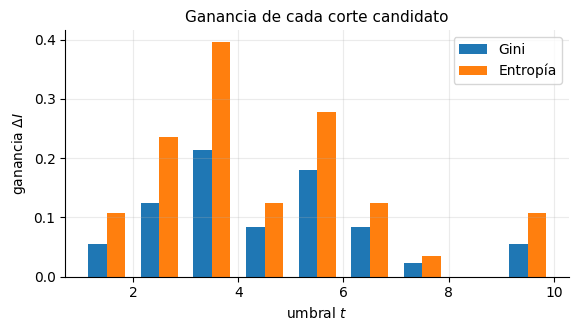

Mejor umbral (Gini): 3.5 | (entropía): 3.5


In [49]:
def gini(y):
    y = np.asarray(y, dtype=int)
    if y.size == 0:
        return 0.0
    p = np.bincount(y) / y.size
    return 1.0 - np.sum(p ** 2)

def entropia(y):
    y = np.asarray(y, dtype=int)
    if y.size == 0:
        return 0.0
    p = np.bincount(y) / y.size
    p = p[p > 0]
    return -np.sum(p * np.log2(p))

def ganancia_impureza(y, mascara_izq, impureza=gini):
    yl, yr = y[mascara_izq], y[~mascara_izq]
    n = len(y)
    return impureza(y) - len(yl) / n * impureza(yl) - len(yr) / n * impureza(yr)

x = np.arange(1, 11)
y = np.array([0, 0, 0, 1, 0, 1, 1, 1, 0, 1])
umbrales = (x[:-1] + x[1:]) / 2

tabla = pd.DataFrame({
    "umbral":              umbrales,
    "Gini izq":            [gini(y[x < t]) for t in umbrales],
    "Gini der":            [gini(y[x >= t]) for t in umbrales],
    "Ganancia (Gini)":     [ganancia_impureza(y, x < t, gini) for t in umbrales],
    "Ganancia (entropía)": [ganancia_impureza(y, x < t, entropia) for t in umbrales],
}).round(4) + 0.0
print(f"Impureza del nodo raíz -> Gini = {gini(y):.3f} | entropía = {entropia(y):.3f}")
display(tabla)

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ancho = 0.35
ax.bar(umbrales - ancho/2, tabla["Ganancia (Gini)"], ancho, label="Gini")
ax.bar(umbrales + ancho/2, tabla["Ganancia (entropía)"], ancho, label="Entropía")
ax.set_xlabel("umbral $t$"); ax.set_ylabel("ganancia $\\Delta I$"); ax.legend()
ax.set_title("Ganancia de cada corte candidato"); plt.show()
print("Mejor umbral (Gini):", umbrales[tabla["Ganancia (Gini)"].idxmax()],
      "| (entropía):", umbrales[tabla["Ganancia (entropía)"].idxmax()])

## 1.3 El algoritmo de construcción (CART)

El algoritmo de *Classification And Regression Trees* (Breiman et al., 1984) es **codicioso** (*greedy*) y **recursivo**:

```
construir(D, profundidad):
    si criterio_de_paro(D, profundidad):          # pureza, profundidad máxima, nº mínimo de datos...
        devolver hoja(valor(D))
    (j*, t*) = argmax_{j, t}  Ganancia(D; j, t)  # se prueban todas las variables y umbrales
    D_L = {x en D : x_j < t*}   ;   D_R = D \ D_L
    devolver nodo(j*, t*, construir(D_L, prof+1), construir(D_R, prof+1))
```

Observaciones:

* **Codicioso:** cada corte se elige por su mejor ganancia inmediata, sin mirar hacia adelante. Encontrar el árbol óptimo es un problema NP-completo (Hyafil y Rivest, 1976), por lo que se usa esta heurística.
* **Umbrales candidatos:** para una variable continua basta con evaluar los puntos medios entre valores consecutivos *distintos* de los datos del nodo.
* **Coste:** ordenar cada variable cuesta $O(n\log n)$ y, con sumas acumuladas, evaluar todos los umbrales cuesta $O(n)$; el trabajo por nivel del árbol es $O(p\,n\log n)$.
* **Criterios de paro típicos:** profundidad máxima, número mínimo de observaciones por hoja o por nodo, ganancia mínima.

### Implementación desde cero de un árbol de regresión

Con el error cuadrático, la mejor partición se obtiene con sumas acumuladas: si un nodo tiene $n$ puntos ordenados por la variable $x_j$, la suma de cuadrados (SSE) de los primeros $k$ es $\sum y_i^2-\left(\sum y_i\right)^2/k$.

In [50]:
class ArbolRegresion:
    """Árbol de regresión CART (criterio: reducción del error cuadrático)."""
    def __init__(self, max_depth=3, min_samples_leaf=1):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf

    def fit(self, X, y):
        self.raiz = self._crecer(np.asarray(X, float), np.asarray(y, float), 0)
        return self

    def _crecer(self, X, y, prof):
        nodo = {"valor": y.mean(), "n": len(y)}
        msl = self.min_samples_leaf
        if prof >= self.max_depth or len(y) < 2 * msl:
            return nodo
        sse_padre = ((y - y.mean()) ** 2).sum()
        mejor = (1e-12, None, None)                      # (ganancia, variable, umbral)
        for j in range(X.shape[1]):
            o = np.argsort(X[:, j], kind="stable")
            xs, ys = X[o, j], y[o]
            n = len(ys)
            cs, cs2 = np.cumsum(ys), np.cumsum(ys ** 2)
            k = np.arange(1, n)                          # tamaño del hijo izquierdo
            sse_l = cs2[:-1] - cs[:-1] ** 2 / k
            sse_r = (cs2[-1] - cs2[:-1]) - (cs[-1] - cs[:-1]) ** 2 / (n - k)
            ganancia = sse_padre - sse_l - sse_r
            valido = (xs[1:] > xs[:-1]) & (k >= msl) & (n - k >= msl)
            ganancia = np.where(valido, ganancia, -np.inf)
            i = int(np.argmax(ganancia))
            if ganancia[i] > mejor[0]:
                mejor = (ganancia[i], j, (xs[i] + xs[i + 1]) / 2)
        if mejor[1] is None:
            return nodo
        _, j, t = mejor
        izq = X[:, j] < t
        nodo.update(j=j, umbral=t,
                    izq=self._crecer(X[izq], y[izq], prof + 1),
                    der=self._crecer(X[~izq], y[~izq], prof + 1))
        return nodo

    def _predecir(self, nodo, X):
        if "j" not in nodo:
            return np.full(len(X), nodo["valor"])
        izq = X[:, nodo["j"]] < nodo["umbral"]
        out = np.empty(len(X))
        out[izq] = self._predecir(nodo["izq"], X[izq])
        out[~izq] = self._predecir(nodo["der"], X[~izq])
        return out

    def predict(self, X):
        return self._predecir(self.raiz, np.asarray(X, float))

# Verificación contra scikit-learn
rng = np.random.default_rng(0)
X = rng.uniform(0, 10, size=(300, 2))
y = np.sin(X[:, 0]) + 0.3 * X[:, 1] + rng.normal(0, 0.2, 300)

for prof in [1, 2, 4, 8]:
    propio = ArbolRegresion(max_depth=prof, min_samples_leaf=3).fit(X, y)
    sk = DecisionTreeRegressor(max_depth=prof, min_samples_leaf=3).fit(X, y)
    dif = np.abs(propio.predict(X) - sk.predict(X)).max()
    print(f"profundidad {prof}: máx |propio - sklearn| = {dif:.2e}")

profundidad 1: máx |propio - sklearn| = 4.44e-16
profundidad 2: máx |propio - sklearn| = 8.88e-16
profundidad 4: máx |propio - sklearn| = 6.66e-16
profundidad 8: máx |propio - sklearn| = 8.88e-16


## 1.4 Fronteras de decisión y sobreajuste

Un árbol puede aproximar fronteras arbitrarias si crece lo suficiente; el precio es el **sobreajuste**: al aumentar la profundidad el error de entrenamiento tiende a cero, mientras que el error en datos nuevos primero baja y luego sube.

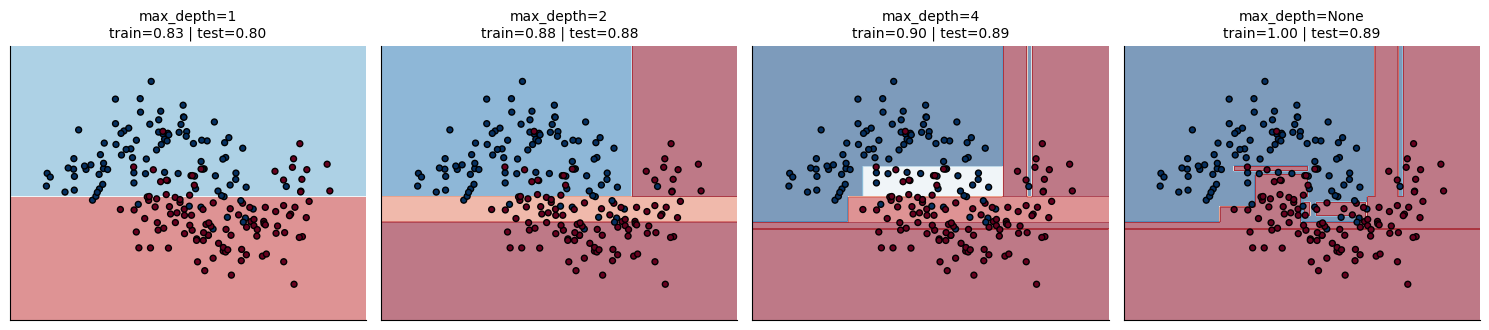

In [51]:
Xm, ym = make_moons(n_samples=400, noise=0.30, random_state=0)
Xtr, Xte, ytr, yte = train_test_split(Xm, ym, test_size=0.5, random_state=0)

def dibujar_frontera(modelo, X, y, ax, titulo=""):
    x0, x1 = X[:, 0].min() - .5, X[:, 0].max() + .5
    y0, y1 = X[:, 1].min() - .5, X[:, 1].max() + .5
    xx, yy = np.meshgrid(np.linspace(x0, x1, 300), np.linspace(y0, y1, 300))
    zz = modelo.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=.55)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="RdBu_r", edgecolor="k", s=18)
    ax.set_title(titulo, fontsize=10); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)

fig, axs = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, prof in zip(axs, [1, 2, 4, None]):
    arbol = DecisionTreeClassifier(max_depth=prof, random_state=0).fit(Xtr, ytr)
    acc_tr, acc_te = arbol.score(Xtr, ytr), arbol.score(Xte, yte)
    dibujar_frontera(arbol, Xtr, ytr, ax, f"max_depth={prof}\ntrain={acc_tr:.2f} | test={acc_te:.2f}")
plt.tight_layout(); plt.show()

**[Interactivo]** Se puede explorar el efecto de la profundidad máxima y del tamaño mínimo de hoja con los controles siguientes.

In [52]:
def explorar_arbol(max_depth=3, min_samples_leaf=1):
    arbol = DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                                   random_state=0).fit(Xtr, ytr)
    fig, ax = plt.subplots(figsize=(4.8, 4))
    dibujar_frontera(arbol, Xtr, ytr, ax,
                     f"profundidad={max_depth}, min_hoja={min_samples_leaf}\n"
                     f"hojas={arbol.get_n_leaves()} | train={arbol.score(Xtr, ytr):.2f} | test={arbol.score(Xte, yte):.2f}")
    plt.show()

interact(explorar_arbol,
         max_depth=IntSlider(min=1, max=15, step=1, value=3, description="max_depth"),
         min_samples_leaf=IntSlider(min=1, max=40, step=1, value=1, description="min_hoja"));

interactive(children=(IntSlider(value=3, description='max_depth', max=15, min=1), IntSlider(value=1, descripti…

### Curva de validación y poda por complejidad

La **poda por coste-complejidad** (Breiman et al., 1984) penaliza el número de hojas $|T|$:

$$
R_\alpha(T)=R(T)+\alpha\,|T| ,
$$

donde $R(T)$ es el error de entrenamiento. Para $\alpha$ creciente se obtienen árboles cada vez más pequeños. (Esta idea reaparece en XGBoost: el término $\gamma T$ del objetivo penaliza cada hoja adicional.)

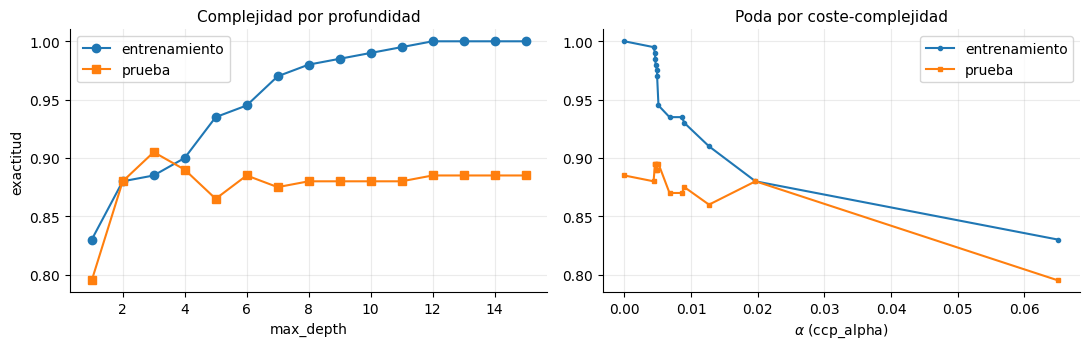

Mejor profundidad en prueba: 3 (exactitud 0.905)
Mejor alpha en prueba:       0.0046 con 27 hojas


In [53]:
profs = range(1, 16)
acc = np.array([[DecisionTreeClassifier(max_depth=d, random_state=0).fit(Xtr, ytr).score(A, b)
                 for A, b in [(Xtr, ytr), (Xte, yte)]] for d in profs])

camino = DecisionTreeClassifier(random_state=0).cost_complexity_pruning_path(Xtr, ytr)
alphas = camino.ccp_alphas[:-1]
acc_a = np.array([[DecisionTreeClassifier(ccp_alpha=a, random_state=0).fit(Xtr, ytr).score(A, b)
                   for A, b in [(Xtr, ytr), (Xte, yte)]] for a in alphas])
hojas = [DecisionTreeClassifier(ccp_alpha=a, random_state=0).fit(Xtr, ytr).get_n_leaves() for a in alphas]

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].plot(profs, acc[:, 0], "o-", label="entrenamiento"); axs[0].plot(profs, acc[:, 1], "s-", label="prueba")
axs[0].set_xlabel("max_depth"); axs[0].set_ylabel("exactitud"); axs[0].legend(); axs[0].set_title("Complejidad por profundidad")
axs[1].plot(alphas, acc_a[:, 0], "o-", ms=3, label="entrenamiento"); axs[1].plot(alphas, acc_a[:, 1], "s-", ms=3, label="prueba")
axs[1].set_xlabel(r"$\alpha$ (ccp_alpha)"); axs[1].set_title("Poda por coste-complejidad"); axs[1].legend()
plt.tight_layout(); plt.show()
print(f"Mejor profundidad en prueba: {list(profs)[acc[:,1].argmax()]} (exactitud {acc[:,1].max():.3f})")
print(f"Mejor alpha en prueba:       {alphas[acc_a[:,1].argmax()]:.4f} con {hojas[acc_a[:,1].argmax()]} hojas")

## 1.5 Limitaciones de un árbol individual

1. **Alta varianza (inestabilidad):** pequeños cambios en los datos producen árboles muy distintos.
2. **Fronteras ortogonales a los ejes:** una frontera diagonal requiere muchos escalones.
3. **No extrapolan:** fuera del rango de entrenamiento la predicción es constante (la de la hoja del extremo).

Los dos primeros puntos motivan los **ensambles** (sección 2).

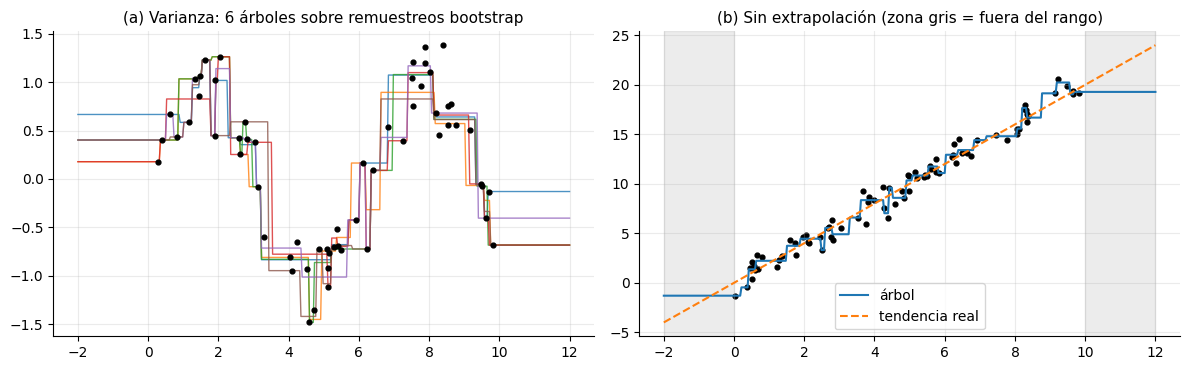

In [54]:
rng = np.random.default_rng(1)
xs = np.sort(rng.uniform(0, 10, 60))
ys = np.sin(xs) + rng.normal(0, 0.3, 60)
grid = np.linspace(-2, 12, 400).reshape(-1, 1)

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
# (a) inestabilidad: árboles ajustados a remuestreos bootstrap
for b in range(6):
    idx = rng.integers(0, len(xs), len(xs))
    arbol = DecisionTreeRegressor(max_depth=5).fit(xs[idx].reshape(-1, 1), ys[idx])
    axs[0].plot(grid, arbol.predict(grid), lw=1, alpha=.8)
axs[0].scatter(xs, ys, c="k", s=12, zorder=3); axs[0].set_title("(a) Varianza: 6 árboles sobre remuestreos bootstrap")

# (b) extrapolación de una tendencia lineal
xl = np.sort(rng.uniform(0, 10, 80)); yl = 2 * xl + rng.normal(0, 1, 80)
arbol = DecisionTreeRegressor(max_depth=5).fit(xl.reshape(-1, 1), yl)
axs[1].scatter(xl, yl, c="k", s=12); axs[1].plot(grid, arbol.predict(grid), label="árbol"); axs[1].plot(grid, 2 * grid, "--", label="tendencia real")
axs[1].axvspan(-2, 0, color="grey", alpha=.15); axs[1].axvspan(10, 12, color="grey", alpha=.15)
axs[1].set_title("(b) Sin extrapolación (zona gris = fuera del rango)"); axs[1].legend()
plt.tight_layout(); plt.show()

---
# 2. Ensambles y *boosting*

## 2.1 Sesgo, varianza y por qué combinar modelos

El error cuadrático esperado de un predictor en un punto $x$ se descompone como

$$
\mathbb{E}\!\left[(y-\hat f(x))^2\right]=\underbrace{\left(f(x)-\mathbb{E}[\hat f(x)]\right)^2}_{\text{sesgo}^2}+\underbrace{\mathrm{Var}[\hat f(x)]}_{\text{varianza}}+\underbrace{\sigma^2}_{\text{ruido}} .
$$

* Un árbol **profundo** tiene sesgo bajo y varianza alta; uno **somero** (un *stump*) tiene sesgo alto y varianza baja.
* **Bagging / Random Forest** (Breiman, 1996; 2001): promedian muchos árboles profundos entrenados sobre remuestreos. El promedio reduce la **varianza** sin aumentar mucho el sesgo. Los árboles se entrenan de forma **independiente** (en paralelo).
* **Boosting**: combina modelos débiles de forma **secuencial**; cada modelo corrige los errores del conjunto anterior, lo que reduce principalmente el **sesgo**.

> **Ejemplo 2.1.** Se estiman el sesgo$^2$ y la varianza de cuatro modelos repitiendo el experimento "generar datos → entrenar → predecir" muchas veces sobre la misma función verdadera.

In [55]:
def f_verdadera(x):
    return np.sin(1.5 * x) + 0.3 * x

def muestra(n, rng, sigma=0.5):
    x = rng.uniform(0, 6, n)
    return x.reshape(-1, 1), f_verdadera(x) + rng.normal(0, sigma, n)

grid_bv = np.linspace(0, 6, 200).reshape(-1, 1)

def sesgo_varianza(fabrica, n_rep=60, n=60, seed=0):
    rng = np.random.default_rng(seed)
    preds = np.empty((n_rep, len(grid_bv)))
    for r in range(n_rep):
        Xs, ys = muestra(n, rng)
        preds[r] = fabrica().fit(Xs, ys).predict(grid_bv)
    sesgo2 = np.mean((preds.mean(0) - f_verdadera(grid_bv.ravel())) ** 2)
    return sesgo2, np.mean(preds.var(0))

modelos = {
    "Árbol, profundidad 1 (stump)":  lambda: DecisionTreeRegressor(max_depth=1),
    "Árbol, profundidad 8":          lambda: DecisionTreeRegressor(max_depth=8),
    "Random Forest (50 árboles)":    lambda: RandomForestRegressor(n_estimators=50, max_depth=8, random_state=0),
    "Gradient Boosting (100 stumps de prof. 2)": lambda: GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=2, random_state=0),
}
res = {nombre: sesgo_varianza(f) for nombre, f in modelos.items()}
df_bv = pd.DataFrame(res, index=["sesgo²", "varianza"]).T
df_bv["sesgo² + varianza"] = df_bv.sum(axis=1)
display(df_bv)

,sesgo²,varianza,sesgo² + varianza
"Árbol, profundidad 1 (stump)",0.1648,0.0650,0.2298
"Árbol, profundidad 8",0.0040,0.2360,0.2400
Random Forest (50 árboles),0.0034,0.1145,0.1178
Gradient Boosting (100 stumps de prof. 2),0.0037,0.1111,0.1148


**Lectura.** El *stump* tiene un sesgo$^2$ grande y poca varianza (subajuste). El árbol profundo tiene sesgo casi nulo pero una varianza alta (sobreajuste). El *random forest* conserva el sesgo bajo del árbol profundo y reduce la varianza aproximadamente a la mitad al promediar. El *gradient boosting* con árboles de profundidad 2 alcanza también un sesgo bajo con una varianza moderada: parte de modelos de sesgo alto y los va corrigiendo.

## 2.2 La idea del *boosting*

Un modelo de *boosting* es un **modelo aditivo** construido por etapas:

$$
F_M(\mathbf{x}) \;=\; F_0(\mathbf{x})+\eta\sum_{m=1}^{M} f_m(\mathbf{x}),
$$

donde cada $f_m$ es un **aprendiz débil** (típicamente un árbol poco profundo) entrenado para corregir las deficiencias de $F_{m-1}$, y $\eta\in(0,1]$ es la tasa de aprendizaje. Las diferentes variantes de boosting se distinguen en *qué* informa a $f_m$ de los errores previos:

| Método | Cómo se comunican los errores | Pérdida implícita |
|---|---|---|
| AdaBoost | pesos sobre las observaciones | exponencial |
| Gradient Boosting | pseudo-residuos (gradiente negativo) | cualquiera derivable |
| XGBoost | gradiente **y** hessiano, con regularización | cualquiera dos veces derivable |

## 2.3 AdaBoost

En AdaBoost discreto (Freund y Schapire, 1997) con etiquetas $y_i\in\{-1,+1\}$ y pesos iniciales $w_i=1/n$, en cada ronda $m$:

1. Entrenar un clasificador débil $h_m$ con los pesos $w_i$.
2. Calcular su error ponderado $\epsilon_m=\dfrac{\sum_i w_i\,\mathbb{1}[h_m(x_i)\neq y_i]}{\sum_i w_i}$.
3. Calcular su peso en el voto: $\alpha_m=\tfrac12\ln\dfrac{1-\epsilon_m}{\epsilon_m}$.
4. Actualizar pesos: $w_i\leftarrow w_i\,e^{-\alpha_m y_i h_m(x_i)}$ y normalizar (los puntos mal clasificados ganan peso).

La predicción final es $H(x)=\mathrm{sign}\!\left(\sum_m\alpha_m h_m(x)\right)$. AdaBoost equivale a minimizar la pérdida exponencial $e^{-yF(x)}$ mediante un procedimiento por etapas (Friedman, Hastie y Tibshirani, 2000), lo que conecta con el *gradient boosting* de la siguiente sección.

> **Ejemplo 2.2.** Implementación con *stumps*. En cada panel el tamaño de cada punto es proporcional a su peso en esa ronda.

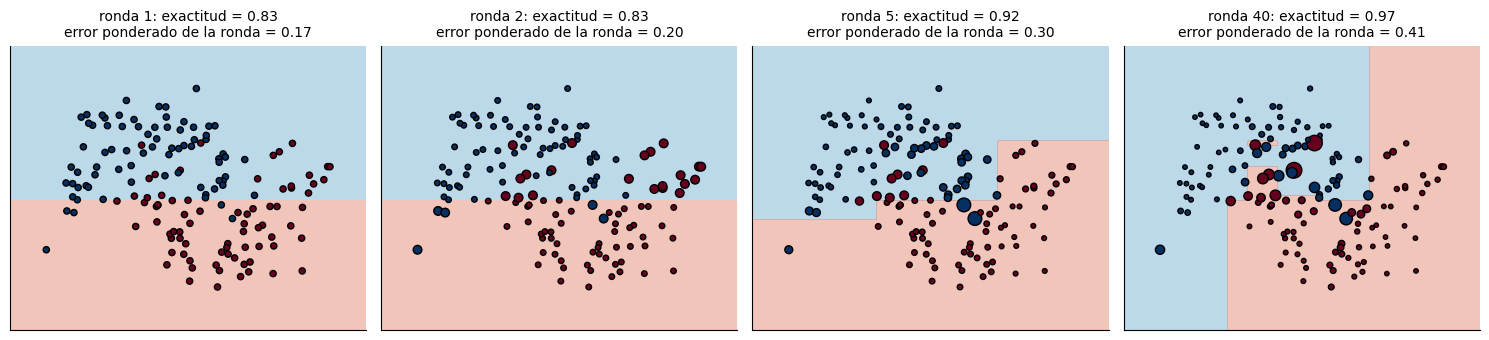

In [56]:
def adaboost_stumps(X, y01, T=30):
    y = 2 * y01 - 1
    n = len(y); w = np.full(n, 1 / n)
    modelos, alphas, historia = [], [], []
    for t in range(T):
        stump = DecisionTreeClassifier(max_depth=1, random_state=0).fit(X, y, sample_weight=w)
        pred = stump.predict(X)
        err = np.clip(np.sum(w * (pred != y)) / np.sum(w), 1e-10, 1 - 1e-10)
        alpha = 0.5 * np.log((1 - err) / err)
        historia.append((w.copy(), err, alpha))
        w = w * np.exp(-alpha * y * pred); w /= w.sum()
        modelos.append(stump); alphas.append(alpha)
    return modelos, alphas, historia

def adaboost_predecir(modelos, alphas, X, m=None):
    m = m or len(modelos)
    return np.sign(sum(a * mod.predict(X) for a, mod in zip(alphas[:m], modelos[:m])))

Xa, ya = make_moons(n_samples=150, noise=0.25, random_state=3)
modelos_ab, alphas_ab, hist_ab = adaboost_stumps(Xa, ya, T=40)

fig, axs = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, m in zip(axs, [1, 2, 5, 40]):
    x0, x1 = Xa[:, 0].min() - .5, Xa[:, 0].max() + .5
    y0, y1 = Xa[:, 1].min() - .5, Xa[:, 1].max() + .5
    xx, yy = np.meshgrid(np.linspace(x0, x1, 250), np.linspace(y0, y1, 250))
    zz = adaboost_predecir(modelos_ab, alphas_ab, np.c_[xx.ravel(), yy.ravel()], m).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-2, 0, 2], cmap="RdBu_r", alpha=.45)
    pesos = hist_ab[m - 1][0]
    ax.scatter(Xa[:, 0], Xa[:, 1], c=ya, cmap="RdBu_r", edgecolor="k", s=10 + 1500 * pesos)
    acc = np.mean(adaboost_predecir(modelos_ab, alphas_ab, Xa, m) == 2 * ya - 1)
    ax.set_title(f"ronda {m}: exactitud = {acc:.2f}\nerror ponderado de la ronda = {hist_ab[m-1][1]:.2f}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout(); plt.show()

## 2.4 *Gradient Boosting*: descenso de gradiente en el espacio de funciones

Friedman (2001) generaliza el boosting a cualquier pérdida derivable $L(y,F)$. La idea: se busca el modelo $F$ que minimiza $\sum_i L(y_i,F(x_i))$ y se interpreta cada valor $F(x_i)$ como un parámetro. Un paso de descenso de gradiente movería $F(x_i)$ en la dirección de $-\partial L/\partial F$; como esa dirección solo está definida en los puntos de entrenamiento, se **ajusta un árbol** a ella para poder generalizarla a nuevos puntos.

**Algoritmo**

1. Inicializar con la constante óptima: $F_0(x)=\arg\min_c\sum_i L(y_i,c)$.
2. Para $m=1,\dots,M$:
    1. Calcular los **pseudo-residuos**: $r_{im}=-\left[\dfrac{\partial L(y_i,F(x_i))}{\partial F(x_i)}\right]_{F=F_{m-1}}$.
    2. Ajustar un árbol de regresión $f_m$ a los pares $(x_i,r_{im})$.
    3. (Opcional) Reemplazar el valor de cada hoja $R_{jm}$ por la constante que minimiza la pérdida: $\arg\min_\rho\sum_{x_i\in R_{jm}}L\left(y_i,F_{m-1}(x_i)+\rho\right)$.
    4. Actualizar: $F_m(x)=F_{m-1}(x)+\eta\,f_m(x)$.

**Casos habituales**

| Pérdida | $L(y,F)$ | Pseudo-residuo $r$ | $F_0$ |
|---|---|---|---|
| Cuadrática (regresión) | $\tfrac12(y-F)^2$ | $y-F$ (el residuo usual) | media de $y$ |
| Absoluta | $\lvert y-F\rvert$ | $\mathrm{signo}(y-F)$ | mediana de $y$ |
| Logística (clasificación), $F$ = log-odds, $p=\sigma(F)$ | $-y\ln p-(1-y)\ln(1-p)$ | $y-p$ | $\ln\frac{\bar y}{1-\bar y}$ |

> **Ejemplo 2.3 (verificación numérica).** Los pseudo-residuos son, por definición, el gradiente negativo de la pérdida. Se comprueba con derivadas numéricas.

In [57]:
def L_cuad(y, F):  return 0.5 * (y - F) ** 2
def L_log(y, F):   # F = log-odds
    p = 1 / (1 + np.exp(-F)); return -(y * np.log(p) + (1 - y) * np.log(1 - p))

def grad_neg_num(L, y, F, eps=1e-6):
    return -(L(y, F + eps) - L(y, F - eps)) / (2 * eps)

y_ej = np.array([1.0, 0.0, 1.0, 0.0]); F_ej = np.array([0.3, -0.5, 1.2, 0.8])
print("Cuadrática : gradiente negativo numérico =", grad_neg_num(L_cuad, y_ej, F_ej))
print("             y - F                       =", y_ej - F_ej)
p_ej = 1 / (1 + np.exp(-F_ej))
print("Logística  : gradiente negativo numérico =", grad_neg_num(L_log, y_ej, F_ej))
print("             y - p                       =", y_ej - p_ej)

Cuadrática : gradiente negativo numérico = [ 0.7  0.5 -0.2 -0.8]
             y - F                       = [ 0.7  0.5 -0.2 -0.8]
Logística  : gradiente negativo numérico = [ 0.4256 -0.3775  0.2315 -0.69  ]
             y - p                       = [ 0.4256 -0.3775  0.2315 -0.69  ]


### Ejemplo numérico paso a paso (pérdida cuadrática, *stumps*, $\eta=0.5$)

Se aplican tres rondas a un conjunto de seis puntos. En cada ronda se calculan los residuos, se ajusta un *stump* a ellos y se actualiza la predicción.

In [58]:
x_ej = np.arange(1, 7, dtype=float)
y_ej = np.array([3.0, 5.0, 4.0, 9.0, 10.0, 8.0])
eta = 0.5

F = np.full_like(y_ej, y_ej.mean())
filas = [{"ronda": 0, **{f"x={int(v)}": F[i] for i, v in enumerate(x_ej)}, "MSE": np.mean((y_ej - F) ** 2), "corte": "-"}]
for m in range(1, 4):
    r = y_ej - F                                              # pseudo-residuos
    stump = DecisionTreeRegressor(max_depth=1).fit(x_ej.reshape(-1, 1), r)
    t = stump.tree_.threshold[0]
    F = F + eta * stump.predict(x_ej.reshape(-1, 1))
    print(f"Ronda {m}: residuos = {np.round(r, 3)} | corte en x < {t} | hojas = {np.round(stump.tree_.value[1:, 0, 0][stump.tree_.children_left[1:] == -1], 3)}")
    filas.append({"ronda": m, **{f"x={int(v)}": F[i] for i, v in enumerate(x_ej)}, "MSE": np.mean((y_ej - F) ** 2), "corte": f"x<{t}"})
print("\nPredicciones acumuladas F_m(x):")
display(pd.DataFrame(filas).set_index("ronda"))
print("y real:", y_ej)

Ronda 1: residuos = [-3.5 -1.5 -2.5  2.5  3.5  1.5] | corte en x < 3.5 | hojas = [-2.5  2.5]
Ronda 2: residuos = [-2.25 -0.25 -1.25  1.25  2.25  0.25] | corte en x < 3.5 | hojas = [-1.25  1.25]
Ronda 3: residuos = [-1.625  0.375 -0.625  0.625  1.625 -0.375] | corte en x < 1.5 | hojas = [-1.625  0.325]

Predicciones acumuladas F_m(x):


,x=1,x=2,x=3,x=4,x=5,x=6,MSE,corte
ronda,,,,,,,,
0,6.5000,6.5000,6.5000,6.5000,6.5000,6.5000,6.9167,-
1,5.2500,5.2500,5.2500,7.7500,7.7500,7.7500,2.2292,x<3.5
2,4.6250,4.6250,4.6250,8.3750,8.3750,8.3750,1.0573,x<3.5
3,3.8125,4.7875,4.7875,8.5375,8.5375,8.5375,0.6612,x<1.5


y real: [ 3.  5.  4.  9. 10.  8.]


### Implementación de *Gradient Boosting* con pérdida cuadrática

Basta con un bucle que ajusta árboles de regresión a los residuos. Se compara con la implementación de scikit-learn.

máx |propio - sklearn| = 0.00e+00


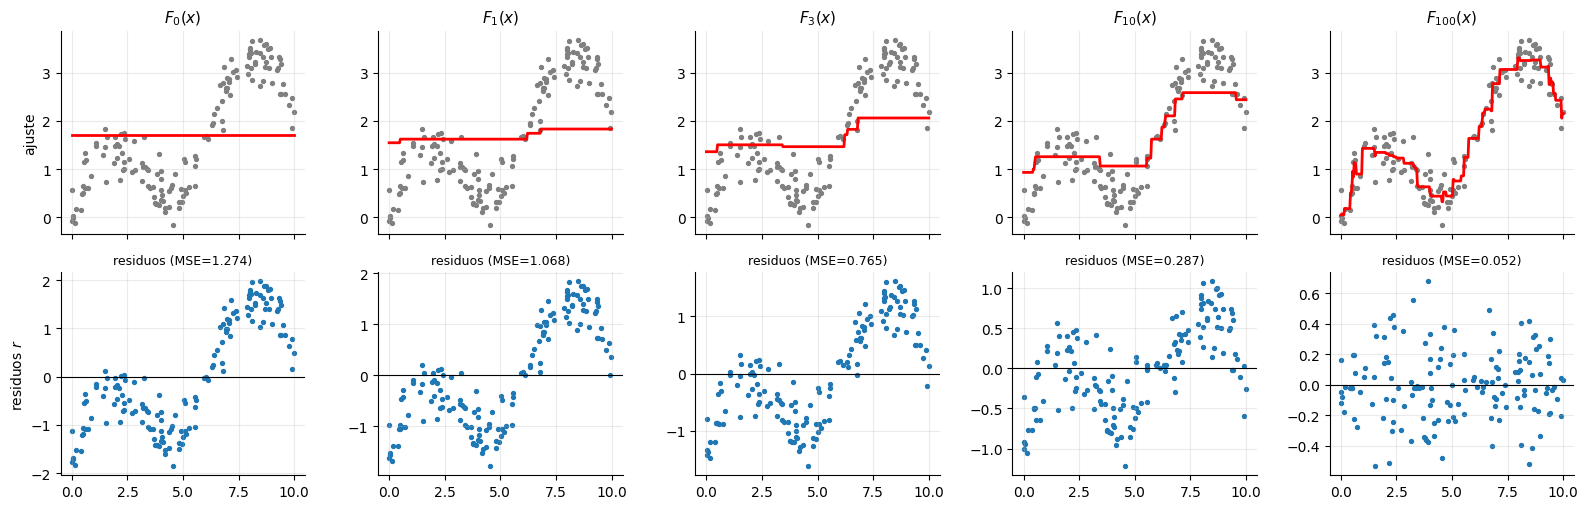

In [59]:
class GradientBoostingL2:
    """Gradient Boosting para regresión con pérdida cuadrática."""
    def __init__(self, n_estimators=100, learning_rate=0.1, max_depth=2):
        self.n_estimators, self.lr, self.max_depth = n_estimators, learning_rate, max_depth

    def fit(self, X, y):
        self.F0 = y.mean()
        F = np.full(len(y), self.F0)
        self.arboles = []
        for _ in range(self.n_estimators):
            r = y - F                                           # pseudo-residuos = -dL/dF
            arbol = DecisionTreeRegressor(max_depth=self.max_depth).fit(X, r)
            F += self.lr * arbol.predict(X)
            self.arboles.append(arbol)
        return self

    def predict(self, X, m=None):
        F = np.full(len(X), self.F0)
        for arbol in self.arboles[:m]:
            F += self.lr * arbol.predict(X)
        return F

rng = np.random.default_rng(5)
Xg = rng.uniform(0, 10, (150, 1)); yg = np.sin(Xg[:, 0]) + 0.3 * Xg[:, 0] + rng.normal(0, 0.3, 150)

propio = GradientBoostingL2(100, 0.1, 2).fit(Xg, yg)
sk = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=2, random_state=0).fit(Xg, yg)
print(f"máx |propio - sklearn| = {np.abs(propio.predict(Xg) - sk.predict(Xg)).max():.2e}")

# Evolución del ajuste
gg = np.linspace(0, 10, 300).reshape(-1, 1)
fig, axs = plt.subplots(2, 5, figsize=(16, 5.2), sharex=True)
for k, m in enumerate([0, 1, 3, 10, 100]):
    ax = axs[0, k]
    ax.scatter(Xg, yg, s=8, c="grey"); ax.plot(gg, propio.predict(gg, m), "r", lw=2)
    ax.set_title(f"$F_{{{m}}}(x)$"); ax2 = axs[1, k]
    res = yg - propio.predict(Xg, m); ax2.scatter(Xg, res, s=8, c="C0"); ax2.axhline(0, c="k", lw=.8)
    ax2.set_title(f"residuos (MSE={np.mean(res**2):.3f})", fontsize=9)
axs[0, 0].set_ylabel("ajuste"); axs[1, 0].set_ylabel("residuos $r$")
plt.tight_layout(); plt.show()

### Tasa de aprendizaje (*shrinkage*) y número de árboles

El factor $\eta$ reduce la contribución de cada árbol. Con $\eta$ pequeño hacen falta más árboles, pero el ajuste suele generalizar mejor (Friedman, 2001). La regla práctica es: **$\eta$ pequeño y $M$ grande**, determinando $M$ con validación (*early stopping*, sección 4).

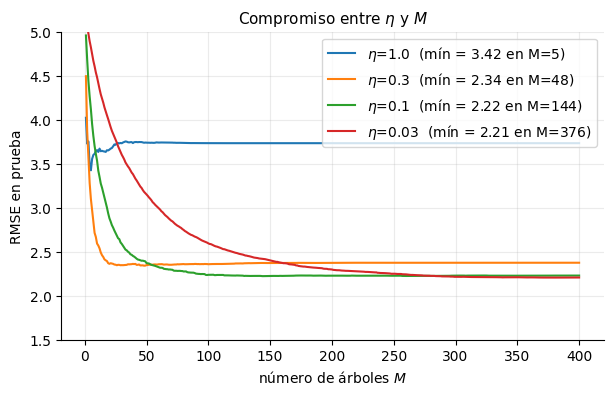

In [60]:
Xs_, ys_ = make_friedman1(n_samples=1200, n_features=10, noise=1.5, random_state=0)
Xs_tr, Xs_te, ys_tr, ys_te = Xs_[:300], Xs_[300:], ys_[:300], ys_[300:]

fig, ax = plt.subplots(figsize=(7, 4))
for lr in [1.0, 0.3, 0.1, 0.03]:
    gb = GradientBoostingRegressor(n_estimators=400, learning_rate=lr, max_depth=3, random_state=0).fit(Xs_tr, ys_tr)
    curva = [rmse(ys_te, p) for p in gb.staged_predict(Xs_te)]
    ax.plot(range(1, 401), curva, label=f"$\\eta$={lr}  (mín = {min(curva):.2f} en M={int(np.argmin(curva))+1})")
ax.set_xlabel("número de árboles $M$"); ax.set_ylabel("RMSE en prueba"); ax.set_ylim(1.5, 5); ax.legend()
ax.set_title("Compromiso entre $\\eta$ y $M$"); plt.show()

**[Interactivo]** Control del número de árboles, la tasa de aprendizaje, la profundidad de los árboles y el submuestreo (*stochastic gradient boosting*, Friedman 2002) sobre un problema unidimensional.

In [61]:
rng = np.random.default_rng(11)
f1d = lambda x: np.sin(x) + 0.3 * x
x_tr1 = rng.uniform(0, 10, 80); y_tr1 = f1d(x_tr1) + rng.normal(0, 0.4, 80)
x_te1 = rng.uniform(0, 10, 300); y_te1 = f1d(x_te1) + rng.normal(0, 0.4, 300)
g1 = np.linspace(0, 10, 400)

def explorar_gb(n_estimators=20, learning_rate=0.3, max_depth=2, subsample=1.0):
    gb = GradientBoostingRegressor(n_estimators=n_estimators, learning_rate=learning_rate,
                                   max_depth=max_depth, subsample=subsample, random_state=0)
    gb.fit(x_tr1.reshape(-1, 1), y_tr1)
    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    ax.scatter(x_tr1, y_tr1, s=14, c="grey", label="entrenamiento")
    ax.plot(g1, f1d(g1), "k--", lw=1, label="función verdadera")
    ax.plot(g1, gb.predict(g1.reshape(-1, 1)), "r", lw=2, label="modelo")
    ax.set_title(f"RMSE entrenamiento = {rmse(y_tr1, gb.predict(x_tr1.reshape(-1,1))):.3f} | "
                 f"RMSE prueba = {rmse(y_te1, gb.predict(x_te1.reshape(-1,1))):.3f}", fontsize=10)
    ax.legend(loc="upper left"); plt.show()

interact(explorar_gb,
         n_estimators=IntSlider(min=1, max=400, step=1, value=20, description="M", continuous_update=False),
         learning_rate=FloatLogSlider(base=10, min=-2, max=0, step=0.1, value=0.3, description="η", continuous_update=False),
         max_depth=IntSlider(min=1, max=6, step=1, value=2, description="max_depth", continuous_update=False),
         subsample=FloatSlider(min=0.3, max=1.0, step=0.1, value=1.0, description="subsample", continuous_update=False));

interactive(children=(IntSlider(value=20, continuous_update=False, description='M', max=400, min=1), FloatLogS…

---
# 3. XGBoost

*eXtreme Gradient Boosting* (Chen y Guestrin, 2016) es una implementación de *gradient boosting* sobre árboles con tres ingredientes que la distinguen de la versión clásica:

| Aspecto | Gradient Boosting clásico | XGBoost |
|---|---|---|
| Información de la pérdida | gradiente (1.er orden) | gradiente **y hessiano** (2.º orden, expansión de Taylor) |
| Regularización | solo implícita (profundidad, $\eta$, submuestreo) | **explícita en el objetivo**: $\gamma T$ y $\tfrac12\lambda\sum w_j^2$ (y L1 opcional) |
| Valor de las hojas | media de residuos (o búsqueda lineal) | solución **cerrada** del problema regularizado |
| Criterio de corte | reducción de MSE sobre residuos | **ganancia** derivada del objetivo regularizado |
| Datos faltantes | requieren imputación | dirección por defecto aprendida (*sparsity-aware*) |
| Búsqueda de cortes | exacta | exacta, aproximada (cuantiles ponderados) o por histogramas |
| Ingeniería | — | bloques de datos en columna, paralelismo, cálculo con conciencia de caché, *out-of-core* |

## 3.1 El objetivo regularizado

El modelo es una suma de $K$ árboles. Cada árbol se escribe como $f(\mathbf{x})=w_{q(\mathbf{x})}$, donde $q:\mathbb{R}^p\to\{1,\dots,T\}$ asigna cada punto a una hoja y $w\in\mathbb{R}^T$ es el vector de valores de hoja. El objetivo a minimizar es

$$
\mathcal{L}(\phi)=\sum_{i=1}^{n} l\!\left(y_i,\hat y_i\right)+\sum_{k=1}^{K}\Omega(f_k),
\qquad
\Omega(f)=\gamma\,T+\tfrac12\,\lambda\sum_{j=1}^{T}w_j^2\;\;\left(+\;\alpha\sum_{j=1}^{T}|w_j|\right).
$$

* $\gamma T$ penaliza el **número de hojas** (cada hoja adicional "cuesta" $\gamma$).
* $\tfrac12\lambda\sum w_j^2$ penaliza **valores de hoja grandes** (regularización L2, tipo *ridge*).
* $\alpha\sum|w_j|$ (opcional) es la regularización L1 (tipo *lasso*).

## 3.2 Derivación: de la pérdida a la ganancia de un corte

Se entrena **aditivamente**. En la iteración $t$ se añade un árbol $f_t$ a la predicción acumulada $\hat y_i^{(t-1)}$:

$$
\mathcal{L}^{(t)}=\sum_{i=1}^{n} l\!\left(y_i,\ \hat y_i^{(t-1)}+f_t(\mathbf{x}_i)\right)+\Omega(f_t).
$$

**Paso 1: expansión de Taylor de segundo orden** de $l$ alrededor de $\hat y_i^{(t-1)}$:

$$
\mathcal{L}^{(t)}\approx\sum_{i=1}^{n}\Big[\,l\!\left(y_i,\hat y_i^{(t-1)}\right)+g_i\,f_t(\mathbf{x}_i)+\tfrac12\,h_i\,f_t(\mathbf{x}_i)^2\Big]+\Omega(f_t),
$$

con
$$
g_i=\frac{\partial\, l(y_i,\hat y)}{\partial \hat y}\Big|_{\hat y^{(t-1)}_i},\qquad
h_i=\frac{\partial^2 l(y_i,\hat y)}{\partial \hat y^2}\Big|_{\hat y^{(t-1)}_i}.
$$

**Paso 2: agrupar por hojas.** Sea $I_j=\{i: q(\mathbf{x}_i)=j\}$ el conjunto de observaciones de la hoja $j$ y $G_j=\sum_{i\in I_j}g_i$, $H_j=\sum_{i\in I_j}h_i$. Eliminando el término constante:

$$
\tilde{\mathcal{L}}^{(t)}=\sum_{j=1}^{T}\Big[G_j\,w_j+\tfrac12\left(H_j+\lambda\right)w_j^2\Big]+\gamma\,T .
$$

**Paso 3: óptimo por hoja.** Cada hoja es una parábola en $w_j$; derivando e igualando a cero:

$$
\boxed{\,w_j^{*}=-\frac{G_j}{H_j+\lambda}\,}
\qquad\Longrightarrow\qquad
\tilde{\mathcal{L}}^{*}=-\tfrac12\sum_{j=1}^{T}\frac{G_j^2}{H_j+\lambda}+\gamma\,T .
$$

(Con regularización L1 el numerador se reemplaza por el *soft-threshold* $\mathrm{sgn}(G_j)\max(|G_j|-\alpha,0)$.)

El valor $\tilde{\mathcal{L}}^{*}$ es una **puntuación de la estructura del árbol** (*structure score* en el artículo original): cuanto menor, mejor árbol. Cumple el mismo papel que la impureza en un árbol de decisión.

## 3.3 Gradientes y hessianos de las pérdidas habituales

| Objetivo | Pérdida $l(y,\hat y)$ | $g_i$ | $h_i$ |
|---|---|---|---|
| `reg:squarederror` | $\tfrac12(y-\hat y)^2$ | $\hat y_i-y_i$ | $1$ |
| `binary:logistic` ($\hat y$ = log-odds, $p=\sigma(\hat y)$) | $-y\ln p-(1-y)\ln(1-p)$ | $p_i-y_i$ | $p_i(1-p_i)$ |

Observaciones: en regresión cuadrática $g_i=-r_i$ (menos el residuo) y $h_i=1$, de modo que $H_j=n_j$ es simplemente el número de observaciones de la hoja. En clasificación logística $h_i\le\tfrac14$ y es máximo cuando el modelo está indeciso ($p=0.5$); los puntos ya bien clasificados con alta confianza ($p\approx0$ o $1$) casi no pesan.

## 3.4 *Similarity score*, ganancia y *cover*

### Similarity score

Cada hoja (o nodo) contribuye a la puntuación con el término $\dfrac{G^2}{H+\lambda}$. En la literatura didáctica se le llama ***similarity score***:

$$
\boxed{\,S(I)=\frac{\left(\sum_{i\in I}g_i\right)^2}{\sum_{i\in I}h_i+\lambda}\,}
\qquad\text{(regresión cuadrática: } S=\frac{\left(\sum_{i\in I}r_i\right)^2}{n_I+\lambda}\text{, con } r_i=y_i-\hat y_i\text{)}.
$$

*Interpretación:* mide cuán **homogéneos** son los gradientes (residuos) dentro del nodo. Si todos tienen el mismo signo se suman y $S$ es grande; si hay residuos positivos y negativos se cancelan y $S$ es pequeño. Un nodo cuyos residuos se cancelan "ya está bien ajustado": no hay nada que corregir con un valor de hoja constante.

El valor de salida de la hoja es $w^*=-G/(H+\lambda)$; en regresión cuadrática es $w^*=\sum r_i/(n+\lambda)$, es decir, la **media de los residuos contraída** por el factor $n/(n+\lambda)$.

### Ganancia (*gain*)

Al comparar un nodo padre $P$ con sus hijos $L$ y $R$ tras un corte:

$$
\boxed{\,\text{Gain}=S_L+S_R-S_P\,}
$$

El artículo original escribe $\tfrac12\left[S_L+S_R-S_P\right]-\gamma$; la biblioteca `xgboost` reporta la ganancia **sin el factor** $\tfrac12$ y la compara directamente con $\gamma$ (esto se verifica experimentalmente más abajo). Un corte se conserva si $\text{Gain}>\gamma$; en caso contrario la rama se **poda**.

* Con $\lambda=0$ la ganancia es siempre $\ge 0$ (desigualdad de Cauchy–Schwarz: $\tfrac{G_L^2}{H_L}+\tfrac{G_R^2}{H_R}\ge\tfrac{(G_L+G_R)^2}{H_L+H_R}$).
* Con $\lambda>0$ la ganancia **puede ser negativa**: $\lambda$ actúa como una poda implícita.

### Cover

El ***cover*** de un nodo es la suma de hessianos de sus observaciones, $\text{cover}=H=\sum_{i\in I}h_i$.

* En regresión cuadrática $h_i=1$, así que el cover es el **número de observaciones**.
* En clasificación logística $\text{cover}=\sum p_i(1-p_i)$: no cuenta puntos, sino cuánta "incertidumbre" hay en el nodo.
* El hiperparámetro `min_child_weight` exige que el cover de cada hijo sea al menos ese valor; un corte que genere un hijo con cover menor se descarta.

> **Ejemplo 3.1 (a mano y con código).** Seis observaciones con una variable $x$. La predicción inicial es $\hat y^{(0)}=0.5$ (el valor `base_score` histórico de XGBoost). Los residuos iniciales son $r_i=y_i-0.5$, y se tiene $g_i=-r_i$, $h_i=1$.

In [62]:
def similitud(G, H, lam):
    return G ** 2 / (H + lam)

def peso_hoja(G, H, lam):
    return -G / (H + lam)

def evaluar_cortes(x, g, h, lam=0.0):
    """Tabla con la ganancia de todos los umbrales candidatos de una variable."""
    o = np.argsort(x, kind="stable")
    xs, gs, hs = x[o], g[o], h[o]
    G, H = gs.sum(), hs.sum()
    filas = []
    for k in range(1, len(xs)):
        if xs[k] == xs[k - 1]:
            continue
        GL, HL = gs[:k].sum(), hs[:k].sum()
        GR, HR = G - GL, H - HL
        filas.append({"umbral": (xs[k - 1] + xs[k]) / 2, "G_L": GL, "H_L": HL, "G_R": GR, "H_R": HR,
                      "S_L": similitud(GL, HL, lam), "S_R": similitud(GR, HR, lam)})
    df = pd.DataFrame(filas)
    df["S_padre"] = similitud(G, H, lam)
    df["Ganancia"] = df["S_L"] + df["S_R"] - df["S_padre"]
    return df

x = np.array([1, 2, 3, 4, 5, 6], dtype=float)
y = np.array([2, 4, 3, 9, 11, 7], dtype=float)
y0 = 0.5
g = y0 - y            # g_i = y_hat - y
h = np.ones_like(y)   # h_i = 1
print("residuos r_i = y - y0:", y - y0)
print(f"Nodo raíz: G = {g.sum():.1f}, H = {h.sum():.0f}")
for lam in [0, 1]:
    print(f"\n--- lambda = {lam}:  S_raíz = G²/(H+λ) = {similitud(g.sum(), h.sum(), lam):.4f}")
    display(evaluar_cortes(x, g, h, lam))

residuos r_i = y - y0: [ 1.5  3.5  2.5  8.5 10.5  6.5]
Nodo raíz: G = -33.0, H = 6

--- lambda = 0:  S_raíz = G²/(H+λ) = 181.5000


,umbral,G_L,H_L,G_R,H_R,S_L,S_R,S_padre,Ganancia
0,1.5,-1.5,1.0,-31.5,5.0,2.25,198.45,181.5,19.2
1,2.5,-5.0,2.0,-28.0,4.0,12.50,196.00,181.5,27.0
2,3.5,-7.5,3.0,-25.5,3.0,18.75,216.75,181.5,54.0
3,4.5,-16.0,4.0,-17.0,2.0,64.00,144.50,181.5,27.0
4,5.5,-26.5,5.0,-6.5,1.0,140.45,42.25,181.5,1.2



--- lambda = 1:  S_raíz = G²/(H+λ) = 155.5714


,umbral,G_L,H_L,G_R,H_R,S_L,S_R,S_padre,Ganancia
0,1.5,-1.5,1.0,-31.5,5.0,1.1250,165.3750,155.5714,10.9286
1,2.5,-5.0,2.0,-28.0,4.0,8.3333,156.8000,155.5714,9.5619
2,3.5,-7.5,3.0,-25.5,3.0,14.0625,162.5625,155.5714,21.0536
3,4.5,-16.0,4.0,-17.0,2.0,51.2000,96.3333,155.5714,-8.0381
4,5.5,-26.5,5.0,-6.5,1.0,117.0417,21.1250,155.5714,-17.4048


**Lectura de la tabla.** Con $\lambda=0$ el mejor corte es $x<3.5$ (separa claramente los valores bajos de los altos). Con $\lambda=1$ el mejor corte sigue siendo el mismo, pero la ganancia disminuye, porque los denominadores $H+\lambda$ crecen.

Se calculan ahora, a mano, los valores de las hojas y se verifica contra la biblioteca. Además, se examina qué ocurre al intentar dividir la hoja izquierda ($x<3.5$) con y sin regularización.

In [63]:
umbral = 3.5
izq = x < umbral
for lam in [0, 1]:
    wL = peso_hoja(g[izq].sum(), h[izq].sum(), lam)
    wR = peso_hoja(g[~izq].sum(), h[~izq].sum(), lam)
    print(f"lambda={lam}: w_izq = {wL:.4f}, w_der = {wR:.4f}  ->  predicciones con eta=1: {y0 + wL:.4f} y {y0 + wR:.4f}")

print("\nEl valor w = Σr/(n+λ): para λ=1 en la hoja izquierda, Σr = ", (y - y0)[izq].sum(),
      "y n+λ =", izq.sum() + 1, "->", (y - y0)[izq].sum() / (izq.sum() + 1))

print("\nCortes dentro de la hoja izquierda (x<3.5):")
for lam in [0, 1]:
    print(f"  lambda={lam}: ganancias de los cortes =", evaluar_cortes(x[izq], g[izq], h[izq], lam)["Ganancia"].round(4).tolist())

lambda=0: w_izq = 2.5000, w_der = 8.5000  ->  predicciones con eta=1: 3.0000 y 9.0000
lambda=1: w_izq = 1.8750, w_der = 6.3750  ->  predicciones con eta=1: 2.3750 y 6.8750

El valor w = Σr/(n+λ): para λ=1 en la hoja izquierda, Σr =  7.5 y n+λ = 4 -> 1.875

Cortes dentro de la hoja izquierda (x<3.5):
  lambda=0: ganancias de los cortes = [1.5, 0.0]
  lambda=1: ganancias de los cortes = [-0.9375, -2.6042]


In [64]:
def arbol_xgb(lam, gamma=0.0, max_depth=2):
    m = xgb.XGBRegressor(n_estimators=1, max_depth=max_depth, learning_rate=1.0, reg_lambda=lam, gamma=gamma,
                         min_child_weight=0, base_score=0.5, tree_method="exact")
    m.fit(x.reshape(-1, 1), y)
    return m, m.get_booster().trees_to_dataframe()[["Node", "Feature", "Split", "Yes", "No", "Gain", "Cover"]]

for lam in [0, 1]:
    m, df = arbol_xgb(lam)
    print(f"=== XGBoost, lambda = {lam}  (en las filas 'Leaf', la columna Gain contiene el valor de la hoja)")
    display(df)
    print("predicciones:", m.predict(x.reshape(-1, 1)))

=== XGBoost, lambda = 0  (en las filas 'Leaf', la columna Gain contiene el valor de la hoja)


,Node,Feature,Split,Yes,No,Gain,Cover
0,0,f0,3.5,0-1,0-2,54.0,6.0
1,1,f0,1.5,0-3,0-4,1.5,3.0
2,2,f0,5.5,0-5,0-6,6.0,3.0
3,3,Leaf,<NA>,<NA>,<NA>,1.5,1.0
4,4,Leaf,<NA>,<NA>,<NA>,3.0,2.0
5,5,Leaf,<NA>,<NA>,<NA>,9.5,2.0
6,6,Leaf,<NA>,<NA>,<NA>,6.5,1.0


predicciones: [ 2.   3.5  3.5 10.  10.   7. ]
=== XGBoost, lambda = 1  (en las filas 'Leaf', la columna Gain contiene el valor de la hoja)


,Node,Feature,Split,Yes,No,Gain,Cover
0,0,f0,3.5,0-1,0-2,21.0536,6.0
1,1,Leaf,<NA>,<NA>,<NA>,1.875,3.0
2,2,Leaf,<NA>,<NA>,<NA>,6.375,3.0


predicciones: [2.375 2.375 2.375 6.875 6.875 6.875]


**Verificación.** Las ganancias y los *cover* de la biblioteca coinciden con la tabla calculada a mano (por ejemplo, para $\lambda=1$ la ganancia del corte raíz y los valores de hoja $\hat y^{(0)}+w$). Además se observa lo anunciado: con $\lambda=1$ el árbol **no se divide más** porque las ganancias de los cortes internos son negativas, mientras que con $\lambda=0$ el árbol crece hasta `max_depth=2`.

## 3.5 Efecto de $\lambda$ (regularización L2)

De $w^*=-G/(H+\lambda)$ se deducen tres efectos:

1. **Contracción de los valores de hoja:** $|w|$ disminuye al crecer $\lambda$; en el límite $\lambda\to\infty$, $w\to0$ y el árbol no aporta nada.
2. **La contracción es mayor en hojas pequeñas:** el factor $H/(H+\lambda)$ penaliza más a las hojas con poco *cover*; las hojas con muchos datos casi no se ven afectadas. Es una regularización *adaptativa* al tamaño.
3. **Reducción de ganancias y poda implícita:** los cortes que aíslan pocas observaciones pierden ganancia (o la ganancia se vuelve negativa) y dejan de realizarse.

El siguiente gráfico muestra los tres efectos sobre el Ejemplo 3.1.

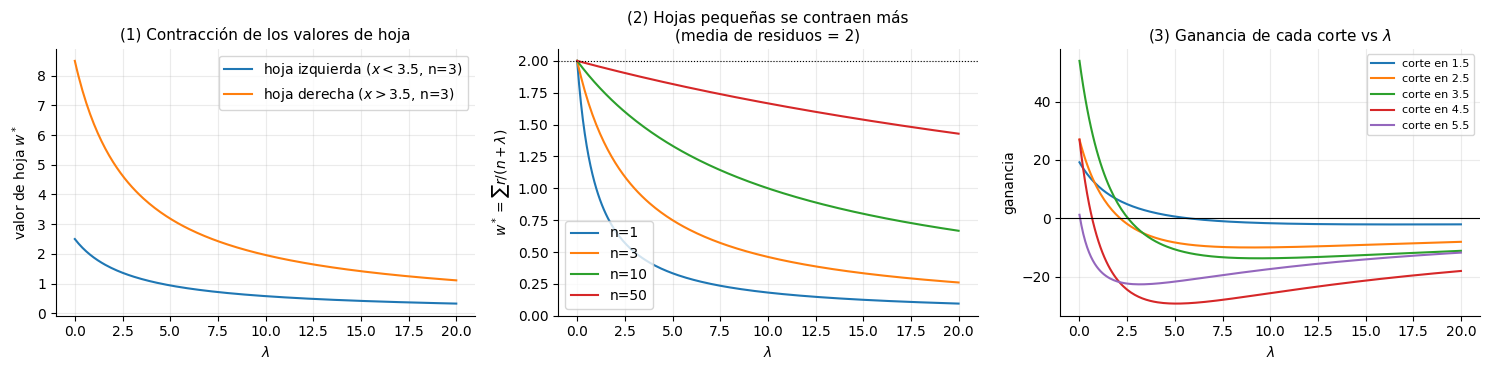

In [65]:
lams = np.linspace(0, 20, 201)
wL_l, wR_l, gan_best = [], [], []
curvas = {}
for lam in lams:
    wL_l.append(peso_hoja(g[izq].sum(), h[izq].sum(), lam)); wR_l.append(peso_hoja(g[~izq].sum(), h[~izq].sum(), lam))
    df = evaluar_cortes(x, g, h, lam)
    gan_best.append(df["Ganancia"].max())
    for t, gn in zip(df["umbral"], df["Ganancia"]):
        curvas.setdefault(t, []).append(gn)

fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
axs[0].plot(lams, wL_l, label="hoja izquierda ($x<3.5$, n=3)"); axs[0].plot(lams, wR_l, label="hoja derecha ($x>3.5$, n=3)")
axs[0].set_xlabel(r"$\lambda$"); axs[0].set_ylabel("valor de hoja $w^*$"); axs[0].set_title("(1) Contracción de los valores de hoja"); axs[0].legend()

# Hojas de distinto tamaño con la misma media de residuo = 2: la contracción n/(n+λ)
for n_h in [1, 3, 10, 50]:
    axs[1].plot(lams, n_h * 2.0 / (n_h + lams), label=f"n={n_h}")
axs[1].axhline(2.0, c="k", ls=":", lw=.8)
axs[1].set_xlabel(r"$\lambda$"); axs[1].set_ylabel(r"$w^*=\sum r/(n+\lambda)$"); axs[1].set_title("(2) Hojas pequeñas se contraen más\n(media de residuos = 2)"); axs[1].legend()

for t, c in curvas.items():
    axs[2].plot(lams, c, label=f"corte en {t}")
axs[2].axhline(0, c="k", lw=.8); axs[2].set_xlabel(r"$\lambda$"); axs[2].set_ylabel("ganancia"); axs[2].set_title("(3) Ganancia de cada corte vs $\\lambda$"); axs[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3.6 Efecto de $\gamma$ (`gamma` o `min_split_loss`) y poda

Un corte se mantiene solo si $\text{Gain}>\gamma$. Así, $\gamma$ es **la mejora mínima de la función de pérdida** que justifica agregar una hoja. A diferencia de $\lambda$, no modifica los valores de hoja de los árboles que sí se construyen: solo decide **cuántos cortes se realizan**.

Se comprueba el umbral exacto en el Ejemplo 3.1 con $\lambda=1$, donde la ganancia del corte raíz es $\approx 21.05$.

In [66]:
gan_raiz = evaluar_cortes(x, g, h, lam=1)["Ganancia"].max()
print(f"Ganancia del corte raíz (lambda=1): {gan_raiz:.4f}")
for gamma in [0, 20, 21, 21.1, 25]:
    m, df = arbol_xgb(lam=1, gamma=gamma)
    print(f"gamma = {gamma:>5}: nº de nodos = {len(df)}  ->  {'se conserva el corte' if len(df) > 1 else 'poda: queda una sola hoja'}")

Ganancia del corte raíz (lambda=1): 21.0536
gamma =     0: nº de nodos = 3  ->  se conserva el corte
gamma =    20: nº de nodos = 3  ->  se conserva el corte
gamma =    21: nº de nodos = 3  ->  se conserva el corte
gamma =  21.1: nº de nodos = 1  ->  poda: queda una sola hoja
gamma =    25: nº de nodos = 1  ->  poda: queda una sola hoja


La poda es la misma regla que $R_\alpha(T)=R(T)+\alpha|T|$ de la sección 1: $\gamma$ es el coste por hoja.

**Observación de implementación (pre-poda vs. post-poda).** En el método clásico `exact` el árbol se construye completo y se poda **de abajo hacia arriba**: una rama con ganancia baja *puede conservarse* si de ella cuelgan cortes con ganancia alta. En el método `hist` (por defecto en versiones recientes) un corte con ganancia $<\gamma$ simplemente **no se realiza** (pre-poda). El siguiente experimento con datos tipo XOR (donde el primer corte tiene ganancia baja pero habilita cortes posteriores con ganancia alta) lo ilustra.

In [67]:
rng = np.random.default_rng(0)
Xx = rng.uniform(-1, 1, (400, 2))
yx = ((Xx[:, 0] > 0) ^ (Xx[:, 1] > 0)).astype(float) * 10

filas = []
for tm in ["exact", "hist"]:
    for gamma in [0, 200]:
        m = xgb.XGBRegressor(n_estimators=1, max_depth=2, learning_rate=1.0, reg_lambda=0, gamma=gamma,
                             min_child_weight=0, base_score=0.5, tree_method=tm).fit(Xx, yx)
        df = m.get_booster().trees_to_dataframe()
        filas.append({"tree_method": tm, "gamma": gamma, "nº de cortes": int((df.Feature != "Leaf").sum()),
                      "ganancias": df.loc[df.Feature != "Leaf", "Gain"].round(1).tolist()})
display(pd.DataFrame(filas))

,tree_method,gamma,nº de cortes,ganancias
0,exact,0,3,"[147.1, 4967.3, 4795.3]"
1,exact,200,3,"[147.1, 4967.3, 4795.3]"
2,hist,0,3,"[136.3, 4951.7, 4722.8]"
3,hist,200,0,[]


Con $\gamma=200$ y `exact`, el corte raíz (ganancia $\approx 147$, menor que $\gamma$) se conserva porque sus hijos tienen ganancias del orden de $5000$; con `hist` el corte raíz no se llega a realizar y el árbol queda reducido a una hoja.

## 3.7 *Cover* y `min_child_weight` en clasificación

En clasificación logística el hessiano es $h_i=p_i(1-p_i)\le 0.25$, de modo que el *cover* de un nodo **no es el número de observaciones**. Con la predicción inicial $p=0.5$ cada punto aporta exactamente $0.25$; como el valor por defecto es `min_child_weight=1`, **cada hijo necesita al menos 4 observaciones** en el primer árbol. Más adelante, a medida que las predicciones se vuelven confiadas ($p\to0$ o $1$) el hessiano de cada punto disminuye y el *cover* de los nodos cae.

> **Ejemplo 3.2.** Ocho puntos con etiquetas binarias, dos árboles, `min_child_weight=1`.

In [68]:
xc = np.arange(1, 9, dtype=float)
yc = np.array([0, 0, 1, 0, 1, 1, 0, 1])
Xc = xc.reshape(-1, 1)

mc = xgb.XGBClassifier(n_estimators=2, max_depth=3, learning_rate=0.5, reg_lambda=1, min_child_weight=1,
                       base_score=0.5, tree_method="exact").fit(Xc, yc)
display(mc.get_booster().trees_to_dataframe()[["Tree", "Node", "Feature", "Split", "Gain", "Cover"]])

# Cover de la raíz del primer árbol: suma de p(1-p) con p = 0.5
p0 = np.full(8, 0.5)
print("Árbol 1, cover de la raíz  = Σ p(1-p) =", np.sum(p0 * (1 - p0)))

# Cover de la raíz del segundo árbol: con las probabilidades tras el primer árbol
m1 = mc.predict(Xc, output_margin=True, iteration_range=(0, 1))
p1 = 1 / (1 + np.exp(-m1))
print("Probabilidades tras el 1.er árbol:", np.round(p1, 3))
print("Árbol 2, cover de la raíz  = Σ p(1-p) =", round(float(np.sum(p1 * (1 - p1))), 4),
      "(en lugar de 8 observaciones)")

,Tree,Node,Feature,Split,Gain,Cover
0,0,0,f0,4.5,1.0,2.0
1,0,1,Leaf,<NA>,-0.25,1.0
2,0,2,Leaf,<NA>,0.25,1.0
3,1,0,Leaf,<NA>,-0.0,1.9691


Árbol 1, cover de la raíz  = Σ p(1-p) = 2.0
Probabilidades tras el 1.er árbol: [0.438 0.438 0.438 0.438 0.562 0.562 0.562 0.562]
Árbol 2, cover de la raíz  = Σ p(1-p) = 1.9691 (en lugar de 8 observaciones)


## 3.8 El algoritmo completo

**Entrenamiento (método *exact greedy*)**

```
Entrada: datos (X, y), pérdida l, hiperparámetros (M, η, max_depth, λ, γ, min_child_weight, base_score)
1.  ŷ_i ← base_score  (en logística: el log-odds correspondiente)
2.  para t = 1, ..., M:
3.      calcular g_i, h_i para todas las observaciones           # gradiente y hessiano de la pérdida
4.      construir un árbol f_t:
5.          para cada nodo (desde la raíz, hasta max_depth):
6.              G, H ← Σ g_i, Σ h_i del nodo ;   S_P ← G² / (H + λ)
7.              para cada variable j:
8.                  ordenar los datos del nodo por x_j
9.                  recorrer los umbrales acumulando (G_L, H_L); (G_R, H_R) ← (G-G_L, H-H_L)
10.                 descartar si H_L < min_child_weight o H_R < min_child_weight
11.                 Gain ← G_L²/(H_L+λ) + G_R²/(H_R+λ) - S_P
12.             elegir el (j, umbral) con mayor Gain; dividir si Gain > 0
13.         podar de abajo hacia arriba las ramas con Gain < γ
14.         valor de cada hoja:  w = -G/(H+λ)
15.     ŷ_i ← ŷ_i + η · f_t(x_i)
Salida: F(x) = base_score + η Σ_t f_t(x)
```

Se implementa a continuación con regresión cuadrática y clasificación binaria, y se compara con la biblioteca (`tree_method="exact"`).

In [69]:
def sigmoide(z):
    return 1 / (1 + np.exp(-z))

class MiXGBoost:
    """XGBoost 'exact greedy' en ~60 líneas: objetivos reg:squarederror y binary:logistic."""
    def __init__(self, n_estimators=10, learning_rate=0.3, max_depth=3, reg_lambda=1.0, gamma=0.0,
                 min_child_weight=1.0, base_score=0.5, objective="reg:squarederror"):
        self.n_estimators, self.eta, self.max_depth = n_estimators, learning_rate, max_depth
        self.lam, self.gamma, self.mcw = reg_lambda, gamma, min_child_weight
        self.base_score, self.objective = base_score, objective

    def _grad_hess(self, y, margen):
        if self.objective == "reg:squarederror":
            return margen - y, np.ones_like(y)
        p = sigmoide(margen)
        return p - y, p * (1 - p)

    def _construir(self, X, g, h, idx, prof):
        G, H = g[idx].sum(), h[idx].sum()
        nodo = {"hoja": True, "w": peso_hoja(G, H, self.lam), "G": G, "H": H, "n": len(idx)}
        if prof >= self.max_depth or len(idx) < 2:
            return nodo
        S_P = similitud(G, H, self.lam)
        mejor = (-np.inf, None, None)
        for j in range(X.shape[1]):
            o = idx[np.argsort(X[idx, j], kind="stable")]
            xs = X[o, j]
            GL, HL = np.cumsum(g[o])[:-1], np.cumsum(h[o])[:-1]
            GR, HR = G - GL, H - HL
            valido = (xs[1:] > xs[:-1]) & (HL >= self.mcw - 1e-6) & (HR >= self.mcw - 1e-6)
            if not valido.any():
                continue
            ganancia = np.where(valido, similitud(GL, HL, self.lam) + similitud(GR, HR, self.lam) - S_P, -np.inf)
            k = int(np.argmax(ganancia))
            if ganancia[k] > mejor[0]:
                mejor = (ganancia[k], j, (xs[k] + xs[k + 1]) / 2)
        ganancia, j, umbral = mejor
        if j is None or ganancia <= 1e-5:
            return nodo
        izq = X[idx, j] < umbral
        nodo.update(hoja=False, j=j, umbral=umbral, ganancia=ganancia,
                    izq=self._construir(X, g, h, idx[izq], prof + 1),
                    der=self._construir(X, g, h, idx[~izq], prof + 1))
        return nodo

    def _podar(self, nodo):
        """Poda de abajo hacia arriba: una rama con Gain <= γ cuyos hijos son hojas se convierte en hoja."""
        if nodo["hoja"]:
            return nodo
        nodo["izq"], nodo["der"] = self._podar(nodo["izq"]), self._podar(nodo["der"])
        if nodo["izq"]["hoja"] and nodo["der"]["hoja"] and nodo["ganancia"] <= self.gamma:
            return {k: nodo[k] for k in ("w", "G", "H", "n")} | {"hoja": True}
        return nodo

    def _pred_arbol(self, nodo, X):
        if nodo["hoja"]:
            return np.full(len(X), nodo["w"])
        izq = X[:, nodo["j"]] < nodo["umbral"]
        out = np.empty(len(X))
        out[izq], out[~izq] = self._pred_arbol(nodo["izq"], X[izq]), self._pred_arbol(nodo["der"], X[~izq])
        return out

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, float)
        self.b0 = self.base_score if self.objective == "reg:squarederror" else np.log(self.base_score / (1 - self.base_score))
        margen = np.full(len(y), self.b0)
        self.arboles = []
        for _ in range(self.n_estimators):
            g, h = self._grad_hess(y, margen)
            arbol = self._podar(self._construir(X, g, h, np.arange(len(y)), 0))
            self.arboles.append(arbol)
            margen += self.eta * self._pred_arbol(arbol, X)
        return self

    def margen(self, X):
        X = np.asarray(X, float)
        m = np.full(len(X), self.b0)
        for a in self.arboles:
            m += self.eta * self._pred_arbol(a, X)
        return m

    def predict(self, X):
        m = self.margen(X)
        return m if self.objective == "reg:squarederror" else sigmoide(m)

    def n_hojas(self):
        def cuenta(n): return 1 if n["hoja"] else cuenta(n["izq"]) + cuenta(n["der"])
        return [cuenta(a) for a in self.arboles]

# ---- Verificación: regresión ----
rng = np.random.default_rng(1)
X = rng.normal(size=(500, 4))
y = np.sin(X[:, 0]) * 3 + X[:, 1] ** 2 + rng.normal(0, 0.3, 500)

print("REGRESIÓN (20 árboles): máx |propio - xgboost|")
for lam, gam, mcw, md_ in [(1, 0, 1, 3), (5, 2, 1, 4), (0, 0, 0, 2), (10, 0, 5, 5)]:
    propio = MiXGBoost(20, 0.3, md_, lam, gam, mcw, base_score=0.5).fit(X, y)
    ref = xgb.XGBRegressor(n_estimators=20, learning_rate=0.3, max_depth=md_, reg_lambda=lam, gamma=gam,
                           min_child_weight=mcw, base_score=0.5, tree_method="exact").fit(X, y)
    print(f"  lambda={lam:>2}, gamma={gam}, min_child_weight={mcw}, max_depth={md_}:  {np.abs(propio.predict(X) - ref.predict(X)).max():.1e}")

# ---- Verificación: clasificación ----
yb = (y > np.median(y)).astype(float)
propio = MiXGBoost(20, 0.3, 3, 1.0, 0.0, 1.0, 0.5, "binary:logistic").fit(X, yb)
ref = xgb.XGBClassifier(n_estimators=20, learning_rate=0.3, max_depth=3, reg_lambda=1, gamma=0, min_child_weight=1,
                        base_score=0.5, tree_method="exact").fit(X, yb)
print(f"\nCLASIFICACIÓN (20 árboles): máx |propio - xgboost| en la probabilidad = {np.abs(propio.predict(X) - ref.predict_proba(X)[:, 1]).max():.1e}")

REGRESIÓN (20 árboles): máx |propio - xgboost|
  lambda= 1, gamma=0, min_child_weight=1, max_depth=3:  1.2e-06
  lambda= 5, gamma=2, min_child_weight=1, max_depth=4:  9.3e-07
  lambda= 0, gamma=0, min_child_weight=0, max_depth=2:  1.6e-06
  lambda=10, gamma=0, min_child_weight=5, max_depth=5:  1.4e-06

CLASIFICACIÓN (20 árboles): máx |propio - xgboost| en la probabilidad = 8.2e-08


Las diferencias son del orden de $10^{-6}$–$10^{-7}$, atribuibles a que la biblioteca acumula estadísticos en precisión simple (`float32`). Esto confirma que las fórmulas de la sección 3.2–3.4 **son** el algoritmo.

> *Nota.* Con empates numéricos exactos entre dos cortes (algo posible en datos muy pequeños o con parámetros extremos como `min_child_weight` igual a un múltiplo exacto de los hessianos) las dos implementaciones pueden elegir cortes distintos con la misma ganancia; no es un error de ninguna de las dos.

**[Interactivo] Explorador de $\lambda$, $\gamma$ y $\eta$.** Sobre un conjunto de 40 puntos con una función escalonada y ruido, se construye **un árbol** con la implementación propia (predicción inicial = media de $y$). El panel izquierdo muestra la curva resultante; el derecho, las ganancias de todos los umbrales candidatos en la raíz y la línea $\gamma$ (los cortes por encima de la línea sobreviven).

In [70]:
rng = np.random.default_rng(21)
xe = np.sort(rng.uniform(0, 10, 40))
ye = np.where(xe < 3, 0.0, np.where(xe < 7, 4.0, 1.5)) + rng.normal(0, 0.5, 40)
Xe = xe.reshape(-1, 1); ge = np.linspace(0, 10, 400).reshape(-1, 1)

def explorar_xgb(reg_lambda=1.0, gamma=0.0, eta=1.0, max_depth=3):
    base = ye.mean()
    mod = MiXGBoost(1, eta, max_depth, reg_lambda, gamma, 0.0, base_score=base).fit(Xe, ye)
    tabla = evaluar_cortes(xe, base - ye, np.ones_like(ye), reg_lambda)
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
    axs[0].scatter(xe, ye, s=14, c="grey"); axs[0].axhline(base, c="C0", ls=":", label=f"predicción inicial = {base:.2f}")
    axs[0].step(ge, mod.predict(ge), "r", lw=2, where="mid", label=f"1 árbol ({mod.n_hojas()[0]} hojas)")
    axs[0].legend(loc="upper right", fontsize=8); axs[0].set_title(f"$\\lambda$={reg_lambda:.1f}, $\\gamma$={gamma:.1f}, $\\eta$={eta:.2f}")
    axs[1].plot(tabla["umbral"], tabla["Ganancia"], "o-", ms=3); axs[1].axhline(gamma, c="r", ls="--", label=r"$\gamma$")
    axs[1].axhline(0, c="k", lw=.6); axs[1].set_xlabel("umbral en la raíz"); axs[1].set_ylabel("ganancia")
    axs[1].set_title("Ganancia de los cortes candidatos (raíz)"); axs[1].legend()
    plt.tight_layout(); plt.show()

interact(explorar_xgb,
         reg_lambda=FloatSlider(min=0, max=60, step=0.5, value=1, description="λ", continuous_update=False),
         gamma=FloatSlider(min=0, max=80, step=1, value=0, description="γ", continuous_update=False),
         eta=FloatSlider(min=0.05, max=1.0, step=0.05, value=1.0, description="η", continuous_update=False),
         max_depth=IntSlider(min=1, max=5, step=1, value=3, description="max_depth", continuous_update=False));

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='λ', max=60.0, step=0.5), Fl…

**Versión estática** del mismo experimento para tres combinaciones de parámetros:

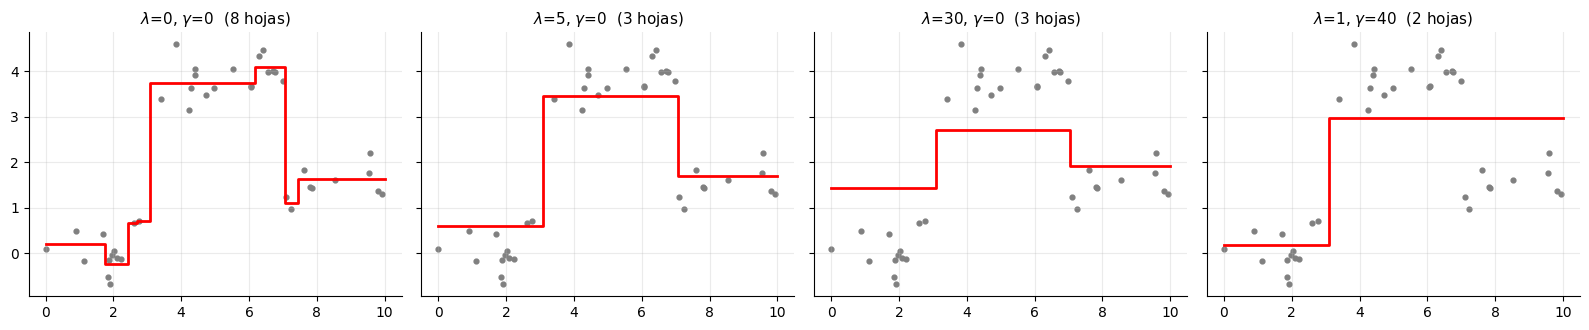

In [71]:
fig, axs = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
for ax, (lam, gam) in zip(axs, [(0, 0), (5, 0), (30, 0), (1, 40)]):
    base = ye.mean()
    mod = MiXGBoost(1, 1.0, 3, lam, gam, 0.0, base_score=base).fit(Xe, ye)
    ax.scatter(xe, ye, s=12, c="grey"); ax.step(ge, mod.predict(ge), "r", lw=2, where="mid")
    ax.set_title(f"$\\lambda$={lam}, $\\gamma$={gam}  ({mod.n_hojas()[0]} hojas)")
plt.tight_layout(); plt.show()

## 3.9 Búsqueda de cortes: exacta, aproximada, histogramas y datos faltantes

**Algoritmo exacto.** Enumera todos los umbrales de todas las variables (el algoritmo de la sección 3.8). Es el más preciso, pero cuesta ordenar en cada nodo y no escala bien a muchos datos.

**Algoritmo aproximado / histogramas** (`tree_method="approx"` / `"hist"`). Se proponen solo unos pocos umbrales candidatos por variable, tomados de **cuantiles** de la distribución, y se acumulan $G$ y $H$ en *bins* (histogramas). `max_bin` fija el número de intervalos. En el artículo original los cuantiles se calculan con un *weighted quantile sketch* en el que **cada observación pesa $h_i$**. La razón es que el objetivo de segundo orden se puede reescribir como un error cuadrático ponderado:

$$
\sum_i\left[g_i f(x_i)+\tfrac12 h_i f(x_i)^2\right]=\sum_i\tfrac12 h_i\left(f(x_i)+\frac{g_i}{h_i}\right)^2+\text{const},
$$

es decir, cada punto es un dato de objetivo $-g_i/h_i$ con peso $h_i$. Por ello, los cuantiles deben repartir el **peso** $h_i$ y no el número de puntos.

**Datos faltantes (*sparsity-aware*).** Para cada corte, los valores ausentes (`NaN`) se envían **todos** a la izquierda o **todos** a la derecha, y se elige la dirección con mayor ganancia (*default direction*). No se imputa.

Una comparación de tiempo y precisión entre métodos:

In [72]:
Xb, yb = make_friedman1(n_samples=40000, n_features=20, noise=1.0, random_state=0)
Xb_tr, Xb_te, yb_tr, yb_te = Xb[:30000], Xb[30000:], yb[:30000], yb[30000:]

filas = []
for tm in ["exact", "approx", "hist"]:
    t0 = time.perf_counter()
    m = xgb.XGBRegressor(n_estimators=50, max_depth=6, learning_rate=0.2, tree_method=tm, n_jobs=4, random_state=0).fit(Xb_tr, yb_tr)
    filas.append({"tree_method": tm, "tiempo de entrenamiento (s)": time.perf_counter() - t0, "RMSE prueba": rmse(yb_te, m.predict(Xb_te))})
display(pd.DataFrame(filas))

,tree_method,tiempo de entrenamiento (s),RMSE prueba
0,exact,5.3430,1.1322
1,approx,0.9272,1.1250
2,hist,1.6110,1.1250


Los métodos `approx` e `hist` son claramente más rápidos que `exact`, con un RMSE prácticamente igual; la diferencia se acentúa al crecer $n$ y $p$.

In [73]:
# Datos faltantes: la dirección por defecto se aprende
rng = np.random.default_rng(3)
n = 1500
x1, x2 = rng.normal(size=n), rng.normal(size=n)
yv = 3.0 * (x1 > 0.3) + x2 + rng.normal(0, 0.2, n)
x1_nan = x1.copy()
x1_nan[(x1 > 1.0) & (rng.random(n) < 0.8)] = np.nan          # ausencia informativa: casi siempre cuando x1 es grande
Xn = np.c_[x1_nan, x2]
print(f"fracción de NaN en x1: {np.isnan(x1_nan).mean():.1%}")

m = xgb.XGBRegressor(n_estimators=1, max_depth=2, learning_rate=1, tree_method="exact", min_child_weight=0).fit(Xn[:1000], yv[:1000])
display(m.get_booster().trees_to_dataframe()[["Node", "Feature", "Split", "Yes", "No", "Missing", "Gain", "Cover"]])

# Comparación con imputar por la media
Xi = Xn.copy(); Xi[np.isnan(Xi)] = np.nanmean(x1_nan)
rm_nan = rmse(yv[1000:], xgb.XGBRegressor(n_estimators=100, max_depth=3, learning_rate=0.1).fit(Xn[:1000], yv[:1000]).predict(Xn[1000:]))
rm_imp = rmse(yv[1000:], xgb.XGBRegressor(n_estimators=100, max_depth=3, learning_rate=0.1).fit(Xi[:1000], yv[:1000]).predict(Xi[1000:]))
print(f"RMSE con NaN nativo = {rm_nan:.3f} | RMSE imputando la media = {rm_imp:.3f}")

fracción de NaN en x1: 12.5%


,Node,Feature,Split,Yes,No,Missing,Gain,Cover
0,0,f0,0.2995,0-1,0-2,0-2,2185.585,1000.0
1,1,f1,0.0022,0-3,0-4,0-3,417.4563,613.0
2,2,f1,-0.0076,0-5,0-6,0-5,260.0102,387.0
3,3,Leaf,<NA>,<NA>,<NA>,<NA>,-1.988,310.0
4,4,Leaf,<NA>,<NA>,<NA>,<NA>,-0.3374,303.0
5,5,Leaf,<NA>,<NA>,<NA>,<NA>,1.0152,190.0
6,6,Leaf,<NA>,<NA>,<NA>,<NA>,2.6614,197.0


RMSE con NaN nativo = 0.237 | RMSE imputando la media = 0.320


En la tabla, `f0` es la variable con valores faltantes. La columna `Missing` indica a qué rama (`Yes` o `No`) se envían los `NaN` en cada nodo. Cuando la ausencia es informativa, la dirección por defecto aprendida suele ser mejor que una imputación arbitraria.

---
# 4. Hiperparámetros de XGBoost

## 4.1 Listado y significado

Los valores por defecto corresponden a la API de scikit-learn (`XGBRegressor`, `XGBClassifier`) de las versiones recientes; los nombres entre paréntesis son los de la API nativa. Los rangos son orientativos.

**Control del boosting**

| Hiperparámetro | Por defecto | ¿Para qué sirve? | Efecto al aumentarlo |
|---|---|---|---|
| `n_estimators` (`num_boost_round`) | 100 | Número de árboles $M$ | Menor sesgo, mayor riesgo de sobreajuste. Se fija con *early stopping* |
| `learning_rate` (`eta`, $\eta$) | 0.3 | Factor de contracción de cada árbol | Aprende más rápido pero generaliza peor; rango típico 0.01–0.3 |
| `early_stopping_rounds` | `None` | Detiene el entrenamiento si la métrica de validación no mejora durante $k$ rondas | — |
| `objective` | `reg:squarederror` / `binary:logistic` | Pérdida $l$ (define $g_i$ y $h_i$) | — |
| `eval_metric` | según objetivo | Métrica de seguimiento (`rmse`, `logloss`, `auc`, `error`…) | — |
| `base_score` | estimado de los datos | Predicción inicial $\hat y^{(0)}$ | Poco relevante con muchos árboles |

**Estructura del árbol**

| Hiperparámetro | Por defecto | ¿Para qué sirve? | Efecto al aumentarlo |
|---|---|---|---|
| `max_depth` | 6 | Profundidad máxima del árbol (controla el orden de las interacciones: un árbol de profundidad $d$ modela interacciones de hasta $d$ variables) | Más complejidad, más sobreajuste; típico 3–10 |
| `min_child_weight` | 1 | *Cover* mínimo $H$ que debe tener cada hijo (en regresión cuadrática = nº mínimo de observaciones) | **Más** regularización (cortes más restringidos) |
| `gamma` (`min_split_loss`, $\gamma$) | 0 | Ganancia mínima para aceptar un corte; costo por hoja | **Más** regularización (árboles más pequeños) |
| `max_leaves` y `grow_policy` | 0; `depthwise` | Con `lossguide` el árbol crece por la hoja de mayor ganancia hasta `max_leaves` hojas (estilo LightGBM) | — |
| `max_delta_step` | 0 (sin límite) | Acota $\lvert w\rvert$ en cada actualización; útil en logística con clases muy desbalanceadas | Menos restricción |
| `max_bin` | 256 | Nº de intervalos del histograma (`hist`/`approx`) | Cortes más finos, más memoria y tiempo |
| `tree_method` | `auto` (≈ `hist`) | Algoritmo de búsqueda de cortes: `exact`, `approx`, `hist` | — |

**Regularización explícita**

| Hiperparámetro | Por defecto | ¿Para qué sirve? | Efecto al aumentarlo |
|---|---|---|---|
| `reg_lambda` ($\lambda$) | 1 | Regularización L2 sobre valores de hoja: $w=-G/(H+\lambda)$ | Hojas más contraídas y menos ganancia |
| `reg_alpha` ($\alpha$) | 0 | Regularización L1: *soft-threshold* sobre $G$ | Más hojas con valor exactamente 0 (modelos más dispersos) |

**Muestreo (decorrelación, estilo *random forest*)**

| Hiperparámetro | Por defecto | ¿Para qué sirve? |
|---|---|---|
| `subsample` | 1 | Fracción de **filas** usada para construir cada árbol (*stochastic gradient boosting*) |
| `colsample_bytree` | 1 | Fracción de **columnas** por árbol |
| `colsample_bylevel`, `colsample_bynode` | 1 | Fracción de columnas por nivel / por nodo |
| `sampling_method` | `uniform` | Esquema de muestreo de filas (`gradient_based` en GPU) |

**Otros**

| Hiperparámetro | Por defecto | ¿Para qué sirve? |
|---|---|---|
| `scale_pos_weight` | 1 | Multiplica el peso ($g_i$ y $h_i$) de la clase positiva; se suele probar (nº negativos)/(nº positivos) |
| `monotone_constraints` | ninguna | Fuerza que la predicción sea monótona creciente o decreciente en una variable |
| `interaction_constraints` | ninguna | Restringe qué variables pueden aparecer juntas en un mismo árbol |
| `booster` | `gbtree` | `gbtree`, `dart` (*dropout* de árboles) o `gblinear` |
| `num_parallel_tree` | 1 | Árboles por ronda (>1 produce un *random forest* potenciado) |
| `random_state`, `n_jobs`, `device` | — | Reproducibilidad, paralelismo, CPU o GPU |

> **Familias de hiperparámetros.** *Complejidad* (`max_depth`, `max_leaves`, `n_estimators`, `learning_rate`), *regularización* (`gamma`, `reg_lambda`, `reg_alpha`, `min_child_weight`), *aleatorización* (`subsample`, `colsample_*`) y *tratamiento del problema* (`objective`, `scale_pos_weight`, restricciones).

## 4.2 Efecto individual de cada hiperparámetro

Se entrena XGBoost sobre el problema de regresión sintético de Friedman (10 variables, de las cuales solo 5 son informativas, con ruido) con un conjunto de entrenamiento pequeño (400 puntos) para que el sobreajuste sea visible. Se varía **un** hiperparámetro cada vez, manteniendo el resto en un punto de partida deliberadamente flexible, y se grafican el RMSE de entrenamiento y de validación.

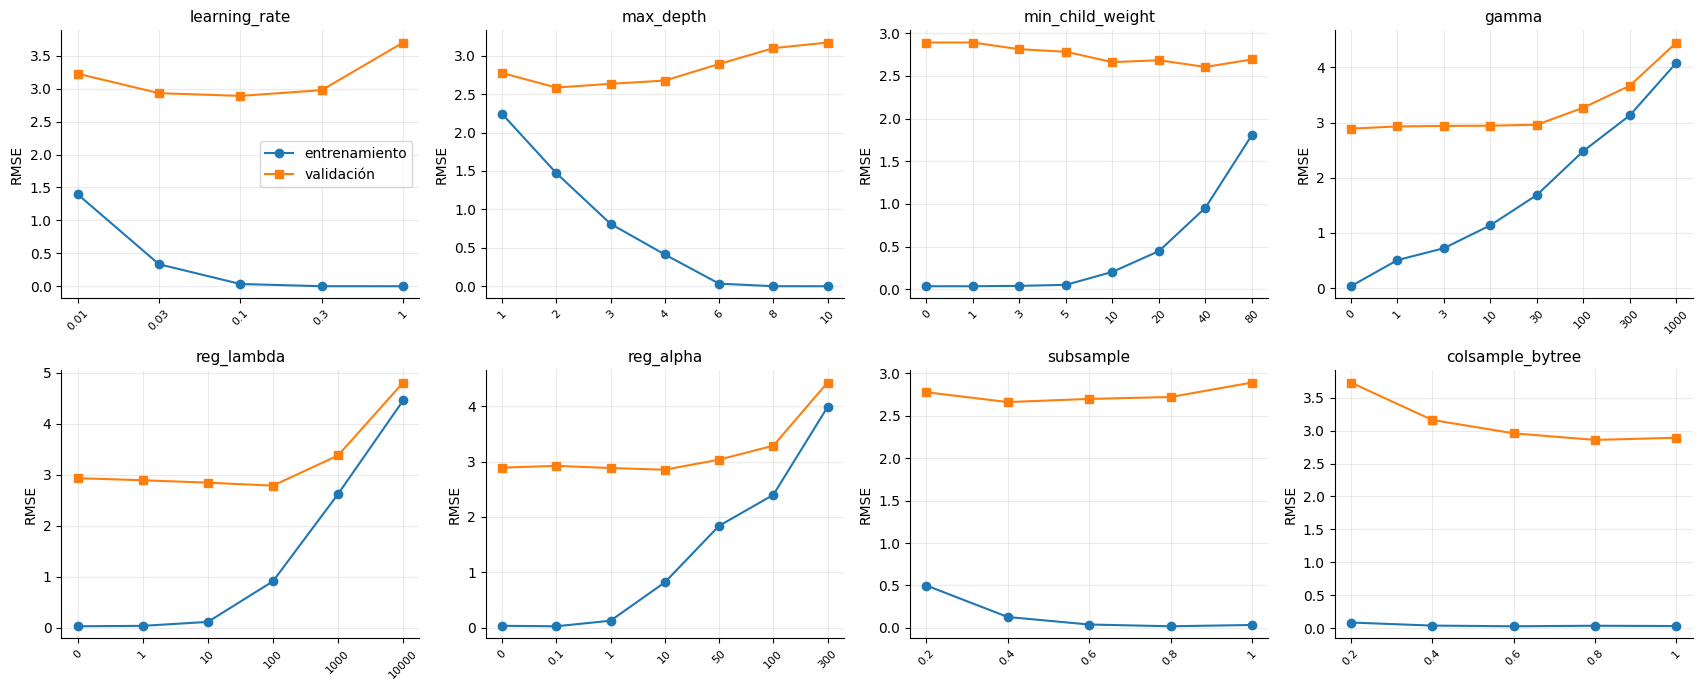

In [74]:
Xf, yf = make_friedman1(n_samples=1000, n_features=10, noise=2.0, random_state=1)
Xf_tr, yf_tr = Xf[:400], yf[:400]
Xf_va, yf_va = Xf[400:], yf[400:]

base = dict(n_estimators=200, learning_rate=0.1, max_depth=6, min_child_weight=1, gamma=0, reg_lambda=1,
            reg_alpha=0, subsample=1.0, colsample_bytree=1.0, tree_method="hist", n_jobs=4, random_state=0)

def barrido(param, valores):
    filas = []
    for v in valores:
        m = xgb.XGBRegressor(**{**base, param: v}).fit(Xf_tr, yf_tr)
        filas.append((v, rmse(yf_tr, m.predict(Xf_tr)), rmse(yf_va, m.predict(Xf_va))))
    return pd.DataFrame(filas, columns=[param, "RMSE entrenamiento", "RMSE validación"])

barridos = {
    "learning_rate":    [0.01, 0.03, 0.1, 0.3, 1.0],
    "max_depth":        [1, 2, 3, 4, 6, 8, 10],
    "min_child_weight": [0, 1, 3, 5, 10, 20, 40, 80],
    "gamma":            [0, 1, 3, 10, 30, 100, 300, 1000],
    "reg_lambda":       [0, 1, 10, 100, 1000, 10000],
    "reg_alpha":        [0, 0.1, 1, 10, 50, 100, 300],
    "subsample":        [0.2, 0.4, 0.6, 0.8, 1.0],
    "colsample_bytree": [0.2, 0.4, 0.6, 0.8, 1.0],
}
resultados = {p: barrido(p, v) for p, v in barridos.items()}

fig, axs = plt.subplots(2, 4, figsize=(17, 7))
for ax, (p, df) in zip(axs.ravel(), resultados.items()):
    pos = np.arange(len(df))
    ax.plot(pos, df["RMSE entrenamiento"], "o-", label="entrenamiento")
    ax.plot(pos, df["RMSE validación"], "s-", label="validación")
    ax.set_xticks(pos); ax.set_xticklabels([f"{v:g}" for v in df[p]], rotation=45, fontsize=8)
    ax.set_title(p); ax.set_ylabel("RMSE")
axs[0, 0].legend()
plt.tight_layout(); plt.show()

In [75]:
for p, df in resultados.items():
    mejor = df.loc[df["RMSE validación"].idxmin()]
    print(f"{p:<17} mejor valor = {mejor[p]:<7g} (RMSE validación = {mejor['RMSE validación']:.3f}, entrenamiento = {mejor['RMSE entrenamiento']:.3f})")

learning_rate     mejor valor = 0.1     (RMSE validación = 2.891, entrenamiento = 0.035)
max_depth         mejor valor = 2       (RMSE validación = 2.585, entrenamiento = 1.473)
min_child_weight  mejor valor = 40      (RMSE validación = 2.604, entrenamiento = 0.956)
gamma             mejor valor = 0       (RMSE validación = 2.891, entrenamiento = 0.035)
reg_lambda        mejor valor = 100     (RMSE validación = 2.785, entrenamiento = 0.908)
reg_alpha         mejor valor = 10      (RMSE validación = 2.853, entrenamiento = 0.819)
subsample         mejor valor = 0.4     (RMSE validación = 2.661, entrenamiento = 0.129)
colsample_bytree  mejor valor = 0.8     (RMSE validación = 2.858, entrenamiento = 0.039)


**Lectura de los gráficos.**

* El punto de partida (`max_depth=6`, sin regularización) **sobreajusta con claridad**: el error de entrenamiento es casi cero y el de validación es mucho mayor.
* `max_depth`, `min_child_weight` y `reg_lambda` muestran la forma típica: al aumentar la regularización el error de **entrenamiento sube** (el modelo se simplifica), mientras que el de **validación** primero baja y luego vuelve a subir. El mejor valor se encuentra en el "codo" donde el modelo deja de memorizar el ruido pero todavía no subajusta. El efecto de `reg_alpha` es más modesto en este problema.
* `learning_rate` interactúa con `n_estimators` (aquí fijo en 200): valores muy pequeños subajustan por haber pocos árboles; valores muy grandes sobreajustan.
* `subsample` moderado (aquí 0.4–0.8) **reduce la varianza** porque decorrela los árboles, aunque aumenta el error de entrenamiento. `colsample_bytree` bajo perjudica aquí porque solo 5 de las 10 variables son informativas: con 20 % de columnas cada árbol ve solo 2 variables y puede quedarse sin ninguna informativa.
* **`gamma`:** en este ejemplo ningún valor mejora la validación. Con pérdida cuadrática la ganancia se mide en unidades de suma de cuadrados (decenas a miles), de modo que $\gamma$ recorta ramas útiles antes de eliminar las ramas de ruido; una misma cifra de `gamma` tiene efectos muy distintos según la pérdida y el tamaño de los datos. En la práctica suele resultar menos efectivo que `min_child_weight` o `reg_lambda`, pero debe explorarse en una escala logarítmica fina cuando se usa.

## 4.3 Número de árboles y *early stopping*

En lugar de elegir $M$ a ciegas, se entrena con un $M$ grande y una **muestra de validación**; el entrenamiento se detiene cuando la métrica de validación no mejora durante `early_stopping_rounds` rondas, y se conserva la mejor iteración.

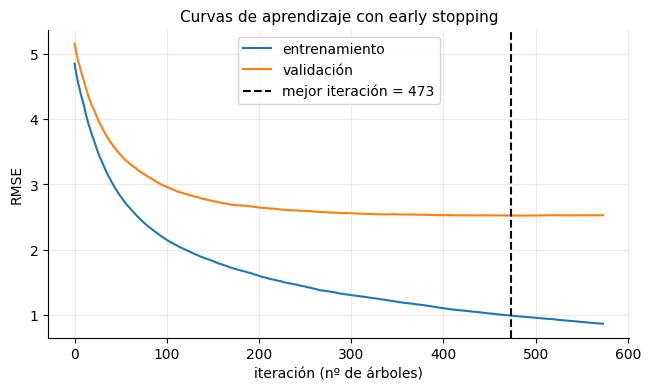

Árboles entrenados: 574 | mejor iteración: 473 | RMSE validación en la mejor iteración: 2.521


In [76]:
m = xgb.XGBRegressor(n_estimators=3000, learning_rate=0.03, max_depth=3, subsample=0.8, colsample_bytree=0.8,
                     early_stopping_rounds=100, eval_metric="rmse", tree_method="hist", random_state=0)
m.fit(Xf_tr, yf_tr, eval_set=[(Xf_tr, yf_tr), (Xf_va, yf_va)], verbose=False)
curvas = m.evals_result()

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(curvas["validation_0"]["rmse"], label="entrenamiento")
ax.plot(curvas["validation_1"]["rmse"], label="validación")
ax.axvline(m.best_iteration, c="k", ls="--", label=f"mejor iteración = {m.best_iteration}")
ax.set_xlabel("iteración (nº de árboles)"); ax.set_ylabel("RMSE"); ax.legend(); ax.set_title("Curvas de aprendizaje con early stopping")
plt.show()
print(f"Árboles entrenados: {len(curvas['validation_0']['rmse'])} | mejor iteración: {m.best_iteration} | RMSE validación en la mejor iteración: {m.best_score:.3f}")

## 4.4 Laboratorio de hiperparámetros

**[Interactivo]** Se ajusta XGBoost sobre una función unidimensional con ruido, variando los hiperparámetros principales. Conviene probar, por ejemplo: subir `reg_lambda` a 100 y observar cómo se aplana la curva; subir `gamma` a 1–3 y observar cómo desaparecen los escalones pequeños (con $\gamma\approx30$ ningún corte supera la ganancia mínima y el modelo colapsa a una constante); subir `min_child_weight` a 20; o bajar `learning_rate` a 0.05 con 50 árboles (subajuste) y luego a 300.

In [77]:
rng = np.random.default_rng(7)
f_lab = lambda x: np.sin(x) + 0.5 * np.sin(3 * x) * np.exp(-0.2 * x)
x_lab = rng.uniform(0, 10, 120); y_lab = f_lab(x_lab) + rng.normal(0, 0.35, 120)
x_lab_te = rng.uniform(0, 10, 500); y_lab_te = f_lab(x_lab_te) + rng.normal(0, 0.35, 500)
g_lab = np.linspace(0, 10, 500)

def laboratorio(n_estimators=50, learning_rate=0.3, max_depth=3, reg_lambda=1.0, gamma=0.0, min_child_weight=1.0, subsample=1.0):
    m = xgb.XGBRegressor(n_estimators=n_estimators, learning_rate=learning_rate, max_depth=max_depth,
                         reg_lambda=reg_lambda, gamma=gamma, min_child_weight=min_child_weight,
                         subsample=subsample, tree_method="hist", random_state=0)
    m.fit(x_lab.reshape(-1, 1), y_lab)
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.scatter(x_lab, y_lab, s=12, c="grey", label="entrenamiento")
    ax.plot(g_lab, f_lab(g_lab), "k--", lw=1, label="función verdadera")
    ax.plot(g_lab, m.predict(g_lab.reshape(-1, 1)), "r", lw=2, label="XGBoost")
    ax.set_title(f"RMSE entrenamiento = {rmse(y_lab, m.predict(x_lab.reshape(-1,1))):.3f} | RMSE prueba = {rmse(y_lab_te, m.predict(x_lab_te.reshape(-1,1))):.3f}", fontsize=10)
    ax.legend(loc="upper right", fontsize=8); plt.show()

interact(laboratorio,
         n_estimators=IntSlider(min=1, max=500, step=1, value=50, description="n_estim.", continuous_update=False),
         learning_rate=FloatLogSlider(base=10, min=-2, max=0, step=0.1, value=0.3, description="η", continuous_update=False),
         max_depth=IntSlider(min=1, max=10, step=1, value=3, description="max_depth", continuous_update=False),
         reg_lambda=FloatLogSlider(base=10, min=-2, max=3, step=0.1, value=1, description="λ", continuous_update=False),
         gamma=FloatSlider(min=0, max=100, step=1, value=0, description="γ", continuous_update=False),
         min_child_weight=FloatSlider(min=0, max=40, step=1, value=1, description="min_child_w", continuous_update=False),
         subsample=FloatSlider(min=0.3, max=1.0, step=0.1, value=1.0, description="subsample", continuous_update=False));

interactive(children=(IntSlider(value=50, continuous_update=False, description='n_estim.', max=500, min=1), Fl…

**Versión estática**: cuatro configuraciones representativas.

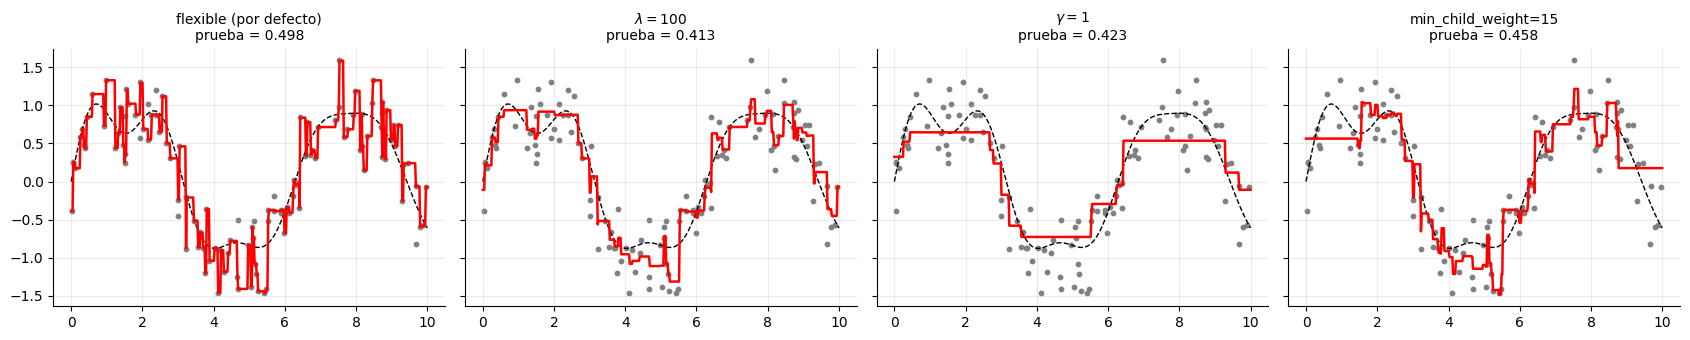

In [78]:
configs = [("flexible (por defecto)",  dict(n_estimators=200, learning_rate=0.3, max_depth=6)),
           ("$\\lambda=100$",           dict(n_estimators=200, learning_rate=0.3, max_depth=6, reg_lambda=100)),
           ("$\\gamma=1$",              dict(n_estimators=200, learning_rate=0.3, max_depth=6, gamma=1)),
           ("min_child_weight=15",      dict(n_estimators=200, learning_rate=0.3, max_depth=6, min_child_weight=15))]
fig, axs = plt.subplots(1, 4, figsize=(17, 3.5), sharey=True)
for ax, (nombre, p) in zip(axs, configs):
    m = xgb.XGBRegressor(tree_method="hist", random_state=0, **p).fit(x_lab.reshape(-1, 1), y_lab)
    ax.scatter(x_lab, y_lab, s=10, c="grey"); ax.plot(g_lab, f_lab(g_lab), "k--", lw=1)
    ax.plot(g_lab, m.predict(g_lab.reshape(-1, 1)), "r", lw=1.8)
    ax.set_title(f"{nombre}\nprueba = {rmse(y_lab_te, m.predict(x_lab_te.reshape(-1, 1))):.3f}", fontsize=10)
plt.tight_layout(); plt.show()

## 4.5 Ejemplos breves de otros hiperparámetros

### `scale_pos_weight` (clases desbalanceadas)

Multiplica el peso de la clase positiva en $g_i$ y $h_i$, de modo que sus errores pesan más en la ganancia y en los valores de hoja. Con un 5 % de positivos, el modelo por defecto tiende a predecir casi siempre la clase negativa.

In [79]:
Xi, yi = make_classification(n_samples=8000, n_features=12, n_informative=4, weights=[0.95, 0.05],
                             flip_y=0.01, class_sep=0.9, random_state=0)
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=0.4, stratify=yi, random_state=0)
print(f"proporción de positivos: {yi.mean():.1%} | neg/pos en entrenamiento = {(yi_tr == 0).sum() / (yi_tr == 1).sum():.1f}")

filas = []
for spw in [1, 5, 19]:
    m = xgb.XGBClassifier(n_estimators=150, max_depth=3, learning_rate=0.1, scale_pos_weight=spw, random_state=0).fit(Xi_tr, yi_tr)
    p = m.predict_proba(Xi_te)[:, 1]; pred = (p > 0.5).astype(int)
    filas.append({"scale_pos_weight": spw, "AUC": roc_auc_score(yi_te, p), "recall (clase +)": recall_score(yi_te, pred),
                  "precisión (clase +)": precision_score(yi_te, pred), "prob. media predicha": p.mean()})
display(pd.DataFrame(filas))

proporción de positivos: 5.6% | neg/pos en entrenamiento = 17.0


,scale_pos_weight,AUC,recall (clase +),precisión (clase +),prob. media predicha
0,1,0.8675,0.2528,0.7627,0.0530
1,5,0.8735,0.4719,0.5122,0.1239
2,19,0.8755,0.6742,0.2733,0.2181


El AUC cambia poco (ordena casi igual), pero el **recall** aumenta a costa de la precisión y las probabilidades quedan **sesgadas hacia arriba** (la prob. media supera el 5 % real). Si se necesitan probabilidades calibradas conviene no usar este parámetro y ajustar el umbral de decisión, o recalibrar después.

### `monotone_constraints`

Impone relaciones monótonas conocidas por el dominio (por ejemplo, "a mayor ingreso, no menor probabilidad de pago"). Se rechazan los cortes que violarían la restricción.

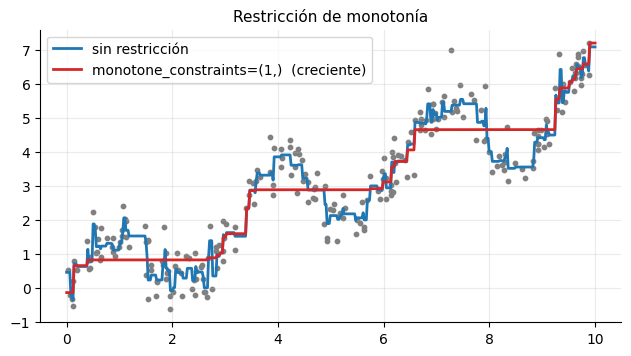

In [80]:
rng = np.random.default_rng(2)
xm_ = np.sort(rng.uniform(0, 10, 250)); ym_ = 0.6 * xm_ + 1.2 * np.sin(2 * xm_) + rng.normal(0, 0.5, 250)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.scatter(xm_, ym_, s=10, c="grey")
for mc_, etiqueta, color in [(None, "sin restricción", "C0"), ((1,), "monotone_constraints=(1,)  (creciente)", "C3")]:
    m = xgb.XGBRegressor(n_estimators=150, max_depth=4, learning_rate=0.1, monotone_constraints=mc_, tree_method="hist", random_state=0)
    m.fit(xm_.reshape(-1, 1), ym_)
    ax.plot(g_lab, m.predict(g_lab.reshape(-1, 1)), color=color, lw=2, label=etiqueta)
ax.legend(); ax.set_title("Restricción de monotonía"); plt.show()

### `grow_policy="lossguide"` y `max_leaves`

En lugar de crecer nivel por nivel (*depthwise*), el árbol se expande siempre por la hoja de **mayor ganancia** hasta alcanzar `max_leaves`. Genera árboles asimétricos que concentran la complejidad donde más reduce la pérdida.

In [81]:
def resumen_arboles(modelo):
    df = modelo.get_booster().trees_to_dataframe()
    hojas = df[df.Feature == "Leaf"].groupby("Tree").size()
    return hojas.mean(), hojas.max()

m_dw = xgb.XGBRegressor(n_estimators=30, max_depth=4, tree_method="hist", random_state=0).fit(Xf_tr, yf_tr)
m_lg = xgb.XGBRegressor(n_estimators=30, max_depth=0, max_leaves=8, grow_policy="lossguide", tree_method="hist", random_state=0).fit(Xf_tr, yf_tr)
for nombre, mm in [("depthwise, max_depth=4", m_dw), ("lossguide, max_leaves=8", m_lg)]:
    mu, mx = resumen_arboles(mm)
    print(f"{nombre:<26} hojas por árbol: media = {mu:.1f}, máximo = {mx} | RMSE validación = {rmse(yf_va, mm.predict(Xf_va)):.3f}")

depthwise, max_depth=4     hojas por árbol: media = 14.1, máximo = 16 | RMSE validación = 2.767
lossguide, max_leaves=8    hojas por árbol: media = 8.0, máximo = 8 | RMSE validación = 2.713


## 4.6 Importancia de variables

XGBoost ofrece varias definiciones de importancia, que responden preguntas distintas:

| Tipo (`importance_type`) | Definición | Qué mide |
|---|---|---|
| `weight` | número de veces que la variable se usa para cortar | frecuencia de uso (favorece variables continuas con muchos umbrales posibles) |
| `gain` | ganancia **media** de los cortes que usan la variable | calidad promedio de sus cortes |
| `total_gain` | ganancia **total** acumulada | contribución total a la reducción de la pérdida |
| `cover` | *cover* **medio** de los nodos donde se usa | cuántos datos (ponderados por $h_i$) afectan sus cortes |
| `total_cover` | *cover* total | — |

La más usada en la práctica es `total_gain`. Ninguna medida es causal ni robusta ante variables correlacionadas; la **importancia por permutación** (sobre datos de validación) y los **valores SHAP** (Lundberg y Lee, 2017) son alternativas más fiables.

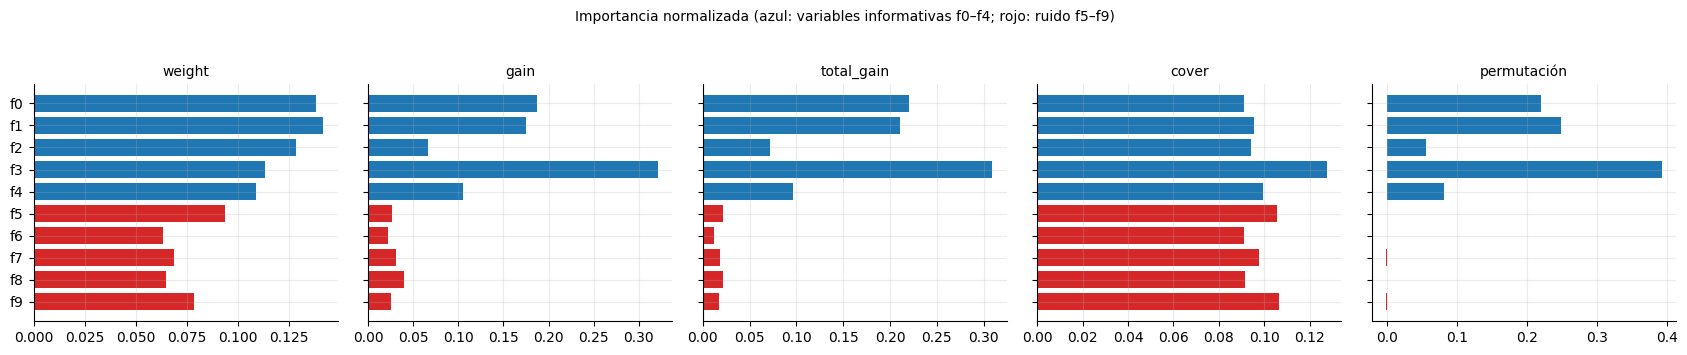

In [82]:
m = xgb.XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=3, subsample=0.8, colsample_bytree=0.8,
                     tree_method="hist", random_state=0).fit(Xf_tr, yf_tr)
nombres = [f"f{i}" for i in range(10)]
tipos = ["weight", "gain", "total_gain", "cover"]
imp = pd.DataFrame({t: pd.Series(m.get_booster().get_score(importance_type=t)) for t in tipos}).reindex(nombres).fillna(0)
perm = permutation_importance(m, Xf_va, yf_va, n_repeats=10, random_state=0)
imp["permutación"] = perm.importances_mean

fig, axs = plt.subplots(1, 5, figsize=(17, 3.4), sharey=True)
for ax, col in zip(axs, imp.columns):
    v = imp[col] / imp[col].sum()
    ax.barh(nombres[::-1], v.values[::-1], color=["C3" if i >= 5 else "C0" for i in range(10)][::-1])
    ax.set_title(col, fontsize=10)
fig.suptitle("Importancia normalizada (azul: variables informativas f0–f4; rojo: ruido f5–f9)", y=1.03, fontsize=10)
plt.tight_layout(); plt.show()

En el problema de Friedman solo $f_0,\dots,f_4$ influyen en $y$. Las medidas basadas en ganancia (`gain`, `total_gain`) y en permutación separan bien las variables informativas del ruido; `weight` da importancia no despreciable a variables de ruido porque se usan en muchos cortes de baja calidad, y el *cover* medio casi no discrimina entre variables. Conviene, por tanto, no usar `weight` ni `cover` como único criterio de selección de variables.

## 4.7 Receta práctica de ajuste

1. **Punto de partida:** `learning_rate=0.05–0.1`, `max_depth=4–6`, `subsample=0.8`, `colsample_bytree=0.8`, `min_child_weight=1`, `reg_lambda=1`, `gamma=0`.
2. **Número de árboles:** `n_estimators` grande (1000–5000) con `early_stopping_rounds=50–100` sobre un conjunto de validación (o con validación cruzada: `xgb.cv`).
3. **Complejidad:** ajustar `max_depth` y `min_child_weight` (o `max_leaves`).
4. **Regularización:** ajustar `gamma`, `reg_lambda` (y `reg_alpha`) en escala logarítmica.
5. **Aleatorización:** ajustar `subsample` y `colsample_bytree` entre 0.5 y 1.
6. **Refinar:** bajar `learning_rate` (por ejemplo a 0.01–0.02) y recalcular el número de árboles con *early stopping*.
7. Si hay desbalance, elegir la métrica adecuada (AUC-PR, F1) y considerar `scale_pos_weight` o el ajuste del umbral.

Las búsquedas aleatorias o bayesianas suelen ser más eficientes que una rejilla completa. Es importante que el conjunto de validación del *early stopping* **no** sea el mismo que se usa para reportar el rendimiento final.

# 5. Comparación global

Se comparan los cuatro modelos estudiados sobre el mismo problema de regresión (Friedman 1, ruido 1, 3000 observaciones de entrenamiento).

In [83]:
Xc_, yc_ = make_friedman1(n_samples=6000, n_features=10, noise=1.0, random_state=7)
Xc_tr, Xc_va, Xc_te = Xc_[:3000], Xc_[3000:4000], Xc_[4000:]
yc_tr, yc_va, yc_te = yc_[:3000], yc_[3000:4000], yc_[4000:]

def evalua(nombre, modelo, **fit_kw):
    t0 = time.perf_counter(); modelo.fit(Xc_tr, yc_tr, **fit_kw); dt = time.perf_counter() - t0
    return {"modelo": nombre, "RMSE prueba": rmse(yc_te, modelo.predict(Xc_te)), "tiempo (s)": dt}

filas = [
    evalua("Árbol (max_depth=6)", DecisionTreeRegressor(max_depth=6, random_state=0)),
    evalua("Random Forest (300 árboles)", RandomForestRegressor(n_estimators=300, n_jobs=4, random_state=0)),
    evalua("Gradient Boosting sklearn (300, η=0.1, prof. 3)", GradientBoostingRegressor(n_estimators=300, learning_rate=0.1, max_depth=3, random_state=0)),
    evalua("XGBoost (early stopping, η=0.05, prof. 3)",
           xgb.XGBRegressor(n_estimators=3000, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8,
                            early_stopping_rounds=100, tree_method="hist", n_jobs=4, random_state=0),
           eval_set=[(Xc_va, yc_va)], verbose=False),
]
display(pd.DataFrame(filas).set_index("modelo"))

,RMSE prueba,tiempo (s)
modelo,,
Árbol (max_depth=6),2.7219,0.0320
Random Forest (300 árboles),1.7702,8.4241
"Gradient Boosting sklearn (300, η=0.1, prof. 3)",1.2444,6.4287
"XGBoost (early stopping, η=0.05, prof. 3)",1.1758,0.8611


En este experimento los dos métodos de *boosting* superan con claridad al *random forest* y al árbol individual, y XGBoost obtiene el menor RMSE (el mínimo alcanzable es cercano a 1, el desvío del ruido). En general, los ensambles de árboles siguen siendo muy competitivos sobre datos tabulares frente a las redes neuronales (Grinsztajn et al., 2022). Estos resultados dependen del problema y de los hiperparámetros: no constituyen una regla universal.

---
# 6. Ejercicios

Cada ejercicio incluye una celda de código con los datos ya definidos. Los ejercicios 1 a 4 están pensados para resolverse **primero a mano** (con calculadora o con operaciones sencillas de NumPy) y verificarse después con código y con la biblioteca. Las soluciones se encuentran en la sección 7.

---
### Ejercicio 1: Un corte de árbol con Gini y con entropía

Se dispone de 8 observaciones con una variable $x$ y una etiqueta binaria $y$:

| $x$ | 2 | 3 | 5 | 7 | 8 | 10 | 12 | 15 |
|---|---|---|---|---|---|---|---|---|
| $y$ | 0 | 0 | 1 | 0 | 1 | 1 | 1 | 1 |

a) Calcular el índice de Gini y la entropía del nodo raíz.
b) Enumerar los umbrales candidatos y calcular la ganancia de cada uno con Gini y con entropía.
c) ¿Qué umbral elige cada criterio? ¿Coinciden?
d) Verificar con `DecisionTreeClassifier(max_depth=1, criterion=...)`.

In [84]:
x1 = np.array([2, 3, 5, 7, 8, 10, 12, 15], dtype=float)
y1 = np.array([0, 0, 1, 0, 1, 1, 1, 1])

# Escribe aquí tu solución

---
### Ejercicio 2: Dos rondas de *Gradient Boosting* con *stumps*

Datos: $x=(1,2,3,4,5,6,7)$ y $y=(1,\,2,\,1.5,\,6,\,7,\,6.5,\,2)$. Pérdida cuadrática, aprendices de profundidad 1 (*stumps*), $\eta=0.5$ y $F_0=\bar y$.

a) Calcular $F_0$ y los pseudo-residuos de la ronda 1.
b) Encontrar el mejor corte del primer *stump* (el que minimiza la suma de cuadrados) y los valores de sus hojas.
c) Calcular $F_1$, los nuevos residuos y el ECM tras la ronda 1.
d) Repetir para la ronda 2 y calcular el ECM tras la ronda 2.
e) Verificar con `GradientBoostingRegressor(n_estimators=2, learning_rate=0.5, max_depth=1)`.

In [85]:
x2 = np.arange(1, 8, dtype=float)
y2 = np.array([1.0, 2.0, 1.5, 6.0, 7.0, 6.5, 2.0])
eta2 = 0.5

# Escribe aquí tu solución

---
### Ejercicio 3: XGBoost de regresión a mano (*similarity*, ganancia, $\lambda$ y $\gamma$)

Cinco observaciones, predicción inicial $\hat y^{(0)}=0.5$, pérdida cuadrática ($g_i=\hat y_i-y_i$, $h_i=1$):

| $x$ | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| $y$ | 1.0 | 1.5 | 4.5 | 5.5 | 5.0 |

a) Calcular los residuos y el *similarity score* de la raíz con $\lambda=1$.
b) Calcular, para cada umbral candidato, los *similarity scores* de los hijos y la ganancia (con $\lambda=1$).
c) ¿Cuál es el mejor corte? ¿Sobrevive con $\gamma=10$? ¿Y con $\gamma=5$?
d) Con $\gamma=5$, calcular los valores de hoja $w^*$ y las predicciones finales con $\eta=0.3$.
e) Repetir (b) y (c) con $\lambda=0$ y $\gamma=10$. ¿Qué diferencia se observa y por qué?
f) Verificar con `XGBRegressor(n_estimators=1, max_depth=1, ...)`.

In [86]:
x3 = np.array([1, 2, 3, 4, 5], dtype=float)
y3 = np.array([1.0, 1.5, 4.5, 5.5, 5.0])
y0_3 = 0.5

# Escribe aquí tu solución

---
### Ejercicio 4: XGBoost de clasificación, *cover* y `min_child_weight`

Seis observaciones con etiqueta binaria y predicción inicial $p^{(0)}=0.5$ (log-odds $=0$), $\lambda=1$, $\eta=0.3$:

| $x$ | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| $y$ | 0 | 0 | 0 | 1 | 0 | 1 |

a) Calcular $g_i=p_i-y_i$ y $h_i=p_i(1-p_i)$, y el *cover* de la raíz.
b) Para cada umbral candidato, calcular el *cover* de cada hijo. ¿Qué cortes son válidos con `min_child_weight` $=1$, $=0.5$ y $=0$?
c) Calcular la ganancia de todos los cortes válidos para `min_child_weight` $=0.5$ y elegir el mejor.
d) Calcular los valores de hoja, las nuevas probabilidades tras el primer árbol, y el *cover* de la raíz del segundo árbol.
e) Verificar con `XGBClassifier`.

In [87]:
x4 = np.arange(1, 7, dtype=float)
y4 = np.array([0, 0, 0, 1, 0, 1], dtype=float)

# Escribe aquí tu solución

---
### Ejercicio 5: Selección de hiperparámetros con validación

Se genera un problema de clasificación binaria con ruido en las etiquetas, dividido en entrenamiento (60 %), validación (20 %) y prueba (20 %).

a) Entrenar `XGBClassifier` con los valores por defecto y reportar el AUC en entrenamiento y en prueba. ¿Hay sobreajuste?
b) Entrenar con `learning_rate=0.05`, `n_estimators=2000` y *early stopping* (50 rondas) sobre el conjunto de validación. ¿Cuál es la mejor iteración?
c) Buscar la mejor combinación de `max_depth` $\in\{2,3,4,6\}$, `min_child_weight` $\in\{1,5,20\}$ y `reg_lambda` $\in\{1,10,50\}$ según el AUC de validación (con *early stopping* en cada ajuste).
d) Reportar el AUC en prueba del mejor modelo y compararlo con (a).
e) Explicar, usando las fórmulas de la sección 3, por qué aumentar `min_child_weight` o `reg_lambda` tiende a reducir el sobreajuste en este problema.

In [88]:
X5, y5 = make_classification(n_samples=2000, n_features=30, n_informative=6, n_redundant=4,
                             flip_y=0.20, class_sep=0.8, random_state=42)
X5_tmp, X5_te, y5_tmp, y5_te = train_test_split(X5, y5, test_size=0.2, stratify=y5, random_state=0)
X5_tr, X5_va, y5_tr, y5_va = train_test_split(X5_tmp, y5_tmp, test_size=0.25, stratify=y5_tmp, random_state=0)
print(X5_tr.shape, X5_va.shape, X5_te.shape)

# Escribe aquí tu solución

(1200, 30) (400, 30) (400, 30)


# 8. Referencias

**Árboles de decisión**

1. Breiman, L., Friedman, J. H., Olshen, R. A. y Stone, C. J. (1984). *Classification and Regression Trees*. Wadsworth & Brooks/Cole.
2. Quinlan, J. R. (1986). Induction of decision trees. *Machine Learning*, 1(1), 81–106.
3. Hyafil, L. y Rivest, R. L. (1976). Constructing optimal binary decision trees is NP-complete. *Information Processing Letters*, 5(1), 15–17.

**Ensambles y boosting**

4. Breiman, L. (1996). Bagging predictors. *Machine Learning*, 24(2), 123–140.
5. Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32.
6. Freund, Y. y Schapire, R. E. (1997). A decision-theoretic generalization of on-line learning and an application to boosting. *Journal of Computer and System Sciences*, 55(1), 119–139.
7. Friedman, J., Hastie, T. y Tibshirani, R. (2000). Additive logistic regression: a statistical view of boosting. *The Annals of Statistics*, 28(2), 337–407.
8. Friedman, J. H. (2001). Greedy function approximation: a gradient boosting machine. *The Annals of Statistics*, 29(5), 1189–1232.
9. Friedman, J. H. (2002). Stochastic gradient boosting. *Computational Statistics & Data Analysis*, 38(4), 367–378.

**XGBoost**

10. Chen, T. y Guestrin, C. (2016). XGBoost: a scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 785–794. https://doi.org/10.1145/2939672.2939785 (arXiv:1603.02754).
11. Documentación de XGBoost: *Introduction to Boosted Trees* y *XGBoost Parameters*. https://xgboost.readthedocs.io
12. Starmer, J. *StatQuest with Josh Starmer*, serie "XGBoost" (partes 1 a 4). YouTube. (Fuente de la denominación didáctica *similarity score*; en el artículo original la cantidad equivalente se denomina *structure score*.)

**Textos generales y temas complementarios**

13. Hastie, T., Tibshirani, R. y Friedman, J. (2009). *The Elements of Statistical Learning* (2.ª ed.). Springer. (Capítulos 9, 10 y 15.)
14. James, G., Witten, D., Hastie, T. y Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2.ª ed.). Springer. (Capítulo 8.)
15. Pedregosa, F. et al. (2011). Scikit-learn: machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
16. Lundberg, S. M. y Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems (NeurIPS)*, 30.
17. Grinsztajn, L., Oyallon, E. y Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *NeurIPS 2022, Datasets and Benchmarks Track*.
18. Roe, B. P., Yang, H.-J., Zhu, J., Liu, Y., Stancu, I. y McGregor, G. (2005). Boosted decision trees as an alternative to artificial neural networks for particle identification. *Nuclear Instruments and Methods in Physics Research A*, 543(2–3), 577–584. (Aplicación del boosting en física de partículas.)
19. Ke, G. et al. (2017). LightGBM: a highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems (NeurIPS)*, 30. (Implementación alternativa de *gradient boosting* basada en histogramas y crecimiento por hojas, comparable a `hist` y `lossguide` en XGBoost.)